# **DS Main Project**

---

**Student Name:** POORNIMA V
**Batch:** DSBO2

**Project Title:** PM2.5 Air Pollution Prediction Using Machine Learning and Deep Learning: A Comparative Study on Real-World Beijing Air Quality Data

**Project Category:** Deep Learning (Time Series Regression)

**Submission Date:** 05-10-2026

---

<font color="197AA6" size=5px><b>PHASE 1 - Data selection, EDA, data cleaning, data preprocessing</b></font>

*Status: Phase 1 and Phase 2 are complete. Phase 3 (training, experiments and evaluation) is ready to run.*

## **Contents** (click a link to jump)

**Phase 1:** [PHASE 1 - Data Selection, EDA, Data Cleaning, Preprocessing](#scrollTo=ba16d6d5) | [0. Project Setup](#scrollTo=84033e6f) | [1. Problem Definition](#scrollTo=df225439) | [2. Dataset Selection & Understanding](#scrollTo=e85c4701) | [3. Exploratory Data Analysis (EDA)](#scrollTo=9190d989) | [4. Data Cleaning & Preprocessing](#scrollTo=f05e7e92)

**Phase 2:** [PHASE 2 - Feature Extraction & Model Building](#scrollTo=c199f754) | [5. Feature Engineering / Representation](#scrollTo=3e5234a4) | [6. Model Building](#scrollTo=f6329974)

**Phase 3:** [PHASE 3 - Model Training & Evaluation](#scrollTo=c819ebc6) | [7. Model Training](#scrollTo=2c18c15f) | [8. Model Experimentation & Optimization](#scrollTo=07c33bb6) | [9. Model Evaluation](#scrollTo=c6a68c4d)

**Phase 4:** [PHASE 4 - Deployment & Documentation](#scrollTo=5105c56c) | [10. Model Export](#scrollTo=9cd79709) | [11. API Deployment](#scrollTo=486fca86) | [12. Docker Containerization](#scrollTo=2e9508e0) | [13. Documentation](#scrollTo=897138ff) | [14. Conclusion](#scrollTo=9ddd33f2)

*Tip: the Table of contents in the left sidebar of Colab also jumps to every section.*


**Reconnect Google Drive**

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **0. Project Setup (Google Colab + Google Drive)**

Connects Google Drive, creates the project folders and sets the data path.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
# Connect Google Drive, create project folders and set paths
import os
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR  = '/content/drive/MyDrive/beijing-pm25-prediction'
DATA_PATH = BASE_DIR + '/data/raw/PRSA_data_2010.1.1-2014.12.31.csv'

for folder in ['data/raw', 'data/processed', 'notebooks', 'models', 'reports/figures', 'app']:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print('Data file:', DATA_PATH)
print('File found:', os.path.exists(DATA_PATH))

Mounted at /content/drive
Data file: /content/drive/MyDrive/beijing-pm25-prediction/data/raw/PRSA_data_2010.1.1-2014.12.31.csv
File found: True


## **1. Problem Definition**

### **1.1 Business / Real-World Problem Statement**

PM2.5 is very fine dust and smoke in the air (particles smaller than 2.5 micrometres). It goes deep into the lungs and can cause breathing and heart problems. Monitoring stations tell us the pollution level *now*, but people, schools and city authorities need to know the level *in advance* so they can take action (wear a mask, avoid outdoor activity, reduce traffic).

This project uses 5 years of real hourly pollution and weather readings from Beijing to predict the PM2.5 concentration.

---

### **1.2 Project Objectives**

* Understand the real-world problem of air pollution.
* Analyze and preprocess a real-world hourly time series dataset with missing values.
* Build machine learning models (baseline) and deep learning models (LSTM / GRU).
* Compare multiple experiments using MAE, RMSE and R2.
* Deploy the final solution as an API.

---

### **1.3 Target Users / Stakeholders**

**Target Users:** General public and people with asthma or heart conditions, schools and hospitals, city authorities, and environmental agencies.

**PM2.5:** Tiny dust and smoke particles in the air, smaller than 2.5 micrometres, measured in ug/m3. The higher the value, the dirtier the air.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

## **2. Dataset Selection & Understanding**

### **2.1 Dataset Source**

**Dataset Source:** https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data

UCI Machine Learning Repository - Beijing PM2.5 Data.
Reference paper: Liang et al. (2015), Proceedings of the Royal Society A.
Licence: confirm on the dataset page and cite it in the final report.

---

### **2.2 Dataset Description**

* **Number of records:** 43,824 (one row per hour)
* **Number of features:** 13 columns in the CSV file (pollution, weather and time columns)
* **Number of classes:** Not applicable (this is a regression problem; the target is a number)
* **Period:** 1 January 2010 to 31 December 2014
* **Dataset purpose:** Predict PM2.5 concentration from weather and time information
* **Data source:** PM2.5 measured by the US Embassy in Beijing; weather data from Beijing Capital International Airport
* **Known issue:** The pm2.5 column has missing values (written as NA)

---

### **2.3 Dataset Overview**

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
import pandas as pd #Pandas holds the data in a table (a DataFrame) so we can clean and analyse it.

Read the CSV and show its size and first 5 rows.

In [ ]:
df = pd.read_csv(DATA_PATH)

# Shape
print('Shape:', df.shape)

# First 5 rows
display(df.head())

Shape: (43824, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


`info()`: column types and non-empty counts.

In [ ]:
# Info (column names, data types, non-null counts)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  object 
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), object(1)
memory usage: 4.3+ MB


`describe()`: average, minimum and maximum of each number column.

In [ ]:
# Describe (count, mean, min, max of numeric columns)
df.describe()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,41757.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,21912.500000,2012.000000,6.523549,15.727820,11.500000,98.613215,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,12651.043435,1.413842,3.448572,8.799425,6.922266,92.050387,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,1.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,10956.750000,2011.000000,4.000000,8.000000,5.750000,29.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,21912.500000,2012.000000,7.000000,16.000000,11.500000,72.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,32868.250000,2013.000000,10.000000,23.000000,17.250000,137.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,43824.000000,2014.000000,12.000000,31.000000,23.000000,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


**Observations:**

* 43,824 hourly rows and 13 columns (8 integer, 4 float, 1 text).
* Only `pm2.5` has missing values: 2,067 (about 4.7%).
* `cbwd` (wind direction) is the only text column and needs encoding.
* `pm2.5` is right-skewed (mean 98.6, median 72, max 994).
* `No` is only a row number and is not used for prediction.

---

### **2.4 Feature / Data Description**

| **Feature** | **Data Type** | **Description** |
| ----------- | ------------- | --------------- |
| No | Numeric (integer) | Row number (ID only, not used for prediction) |
| year | Numeric (integer) | Year of the reading |
| month | Numeric (integer) | Month of the reading |
| day | Numeric (integer) | Day of the reading |
| hour | Numeric (integer) | Hour of the reading (0-23) |
| pm2.5 | Numeric (float) | PM2.5 concentration in ug/m3 (**target**) |
| DEWP | Numeric (integer) | Dew point (degrees C), related to humidity |
| TEMP | Numeric (float) | Temperature (degrees C) |
| PRES | Numeric (float) | Air pressure (hPa) |
| cbwd | Categorical (object) | Combined wind direction (for example NW, SE, cv) |
| Iws | Numeric (float) | Cumulated wind speed (m/s) |
| Is | Numeric (integer) | Cumulated hours of snow |
| Ir | Numeric (integer) | Cumulated hours of rain |

*Data types checked against `df.info()`.*

---

### **2.5 Target Variable / Class**

**Name:** pm2.5

**Description:** Concentration of fine particles (smaller than 2.5 micrometres) in the air, in ug/m3. A higher value means more polluted air.

**Prediction Goal:** Predict the PM2.5 value (regression) and compare ML and DL models.

---

## **3. Exploratory Data Analysis (EDA)**

Exploring the data with numbers and charts before building models.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

### **3.1 Import Libraries**

NumPy: calculations. Matplotlib and Seaborn: charts.

In [ ]:
# NumPy for calculations, Matplotlib and Seaborn for drawing charts
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid') ## Give all charts a light grid background, so values are easier to read

### **3.2 Load Dataset**

Reload the data and join year, month, day and hour into one date-time column.

In [ ]:
# Reload the data and build one date-time column (used later for time plots)
df = pd.read_csv(DATA_PATH)
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])

print('Shape:', df.shape)
print('From', df['datetime'].min(), 'to', df['datetime'].max())

Shape: (43824, 14)
From 2010-01-01 00:00:00 to 2014-12-31 23:00:00


### **3.3 Dataset Analysis**

Shape, info and describe are in Section 2.3. Here we count the wind directions (`cbwd`).

In [ ]:
print(df['cbwd'].value_counts())

cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64


**Observation:** `cbwd` has 4 categories: SE (34.9%), NW (32.3%), cv (21.4%) and NE (11.4%), with no missing values. It is text, so it is one-hot encoded later.

### **3.4 Missing Value Analysis**

Count the missing values, where they are, and how long the gaps are.

In [ ]:
# How many values are missing in each column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({'missing': missing, 'percent': missing_pct}))

# Which years have the missing pm2.5 values
print(df[df['pm2.5'].isnull()].groupby('year').size())

# Longest run of consecutive missing hours
is_na = df['pm2.5'].isnull()
gap_id = (is_na != is_na.shift()).cumsum()
print('Longest run of missing hours:', is_na.groupby(gap_id).sum().max())

          missing  percent
No              0     0.00
year            0     0.00
month           0     0.00
day             0     0.00
hour            0     0.00
pm2.5        2067     4.72
DEWP            0     0.00
TEMP            0     0.00
PRES            0     0.00
cbwd            0     0.00
Iws             0     0.00
Is              0     0.00
Ir              0     0.00
datetime        0     0.00
year
2010    669
2011    728
2012    489
2013     82
2014     99
dtype: int64
Longest run of missing hours: 155


In [ ]:
gap_lengths = is_na.groupby(gap_id).sum()
gap_lengths = gap_lengths[gap_lengths > 0]

print('Total gaps        :', len(gap_lengths))
print('Gaps up to 6 hours :', (gap_lengths <= 6).sum())
print('Gaps 7 to 24 hours :', ((gap_lengths > 6) & (gap_lengths <= 24)).sum())
print('Gaps over 24 hours :', (gap_lengths > 24).sum())

Total gaps        : 214
Gaps up to 6 hours : 158
Gaps 7 to 24 hours : 36
Gaps over 24 hours : 20


**Observation:**

* Only `pm2.5` has missing values: 2,067 (4.72%), about 91% of them in 2010 to 2012.
* They form 214 gaps: 158 are up to 6 hours, 36 are 7 to 24 hours and 20 are longer than 24 hours (the longest is 155 hours).
* Short gaps can be filled by interpolation. The long gaps need a different treatment (Section 4.1).

### **3.5 Class Distribution (Target Distribution)**

**PM2.5** is tiny dust and smoke (particles smaller than 2.5 micrometres) measured in ug/m3; a higher value means dirtier air. It is a number, not a category, so this is a regression problem and we study how its values are spread.

count    41757.0
mean        98.6
std         92.1
min          0.0
25%         29.0
50%         72.0
75%        137.0
max        994.0
Name: pm2.5, dtype: float64
Skewness: 1.8
Values equal to 0 : 2
Values above 300  : 1759


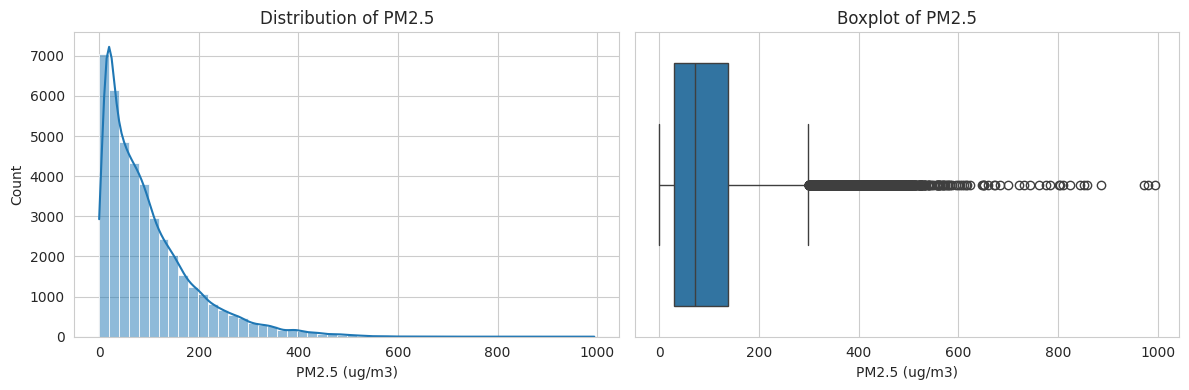

In [ ]:
target = df['pm2.5'].dropna()

print(target.describe().round(1))
print('Skewness:', round(target.skew(), 2))
print('Values equal to 0 :', (target == 0).sum())
print('Values above 300  :', (target > 300).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(target, bins=50, kde=True, ax=ax[0])
ax[0].set_title('Distribution of PM2.5')
ax[0].set_xlabel('PM2.5 (ug/m3)')
sns.boxplot(x=target, ax=ax[1])
ax[1].set_title('Boxplot of PM2.5')
ax[1].set_xlabel('PM2.5 (ug/m3)')
plt.tight_layout()
plt.show()

**Observation:** PM2.5 is strongly right-skewed (skewness 1.8, median 72, mean 98.6). About 4.2% of the values are above 300, which are probably real pollution episodes.

### **3.6 Correlation / Relationship Analysis**

Correlation shows how strongly two columns move together (-1 to +1; near 0 is weak).

pm2.5    1.00
DEWP     0.17
Is       0.02
PRES    -0.05
Ir      -0.05
TEMP    -0.09
Iws     -0.25
Name: pm2.5, dtype: float64


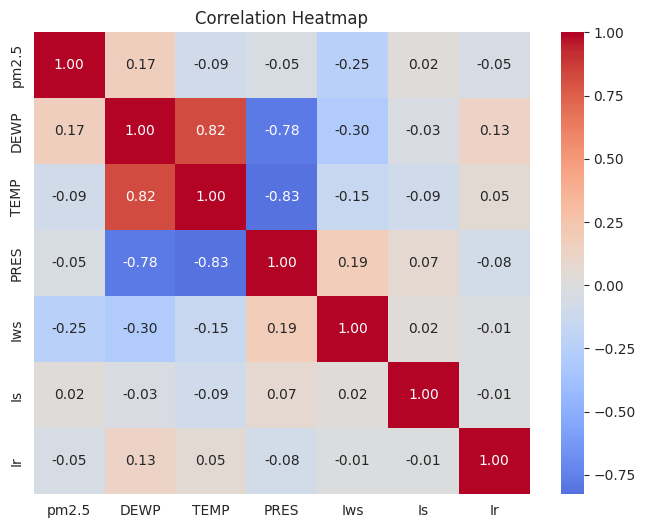

In [ ]:
num_cols = ['pm2.5', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
corr = df[num_cols].corr()

print(corr['pm2.5'].sort_values(ascending=False).round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

**Observation:** All weather correlations with PM2.5 are weak; the strongest are `Iws` (-0.25) and `DEWP` (0.17). DEWP, TEMP and PRES are strongly correlated with each other (0.82, -0.83, -0.78).

### **3.7 Visualizations**

**Visualization 1: PM2.5 Over Time**

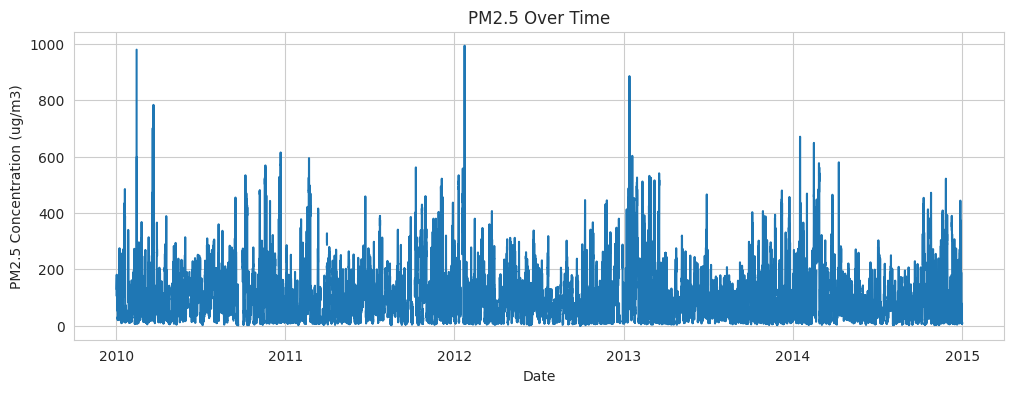

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(df['datetime'], df['pm2.5'])

plt.title('PM2.5 Over Time')
plt.xlabel('Date')
plt.ylabel('PM2.5 Concentration (ug/m3)')

plt.show()

**Observation:** PM2.5 changes constantly with sharp spikes (up to about 1000), mostly early in the year, and shows no long-term trend.

**Visualization 2: Average PM2.5 by Month**

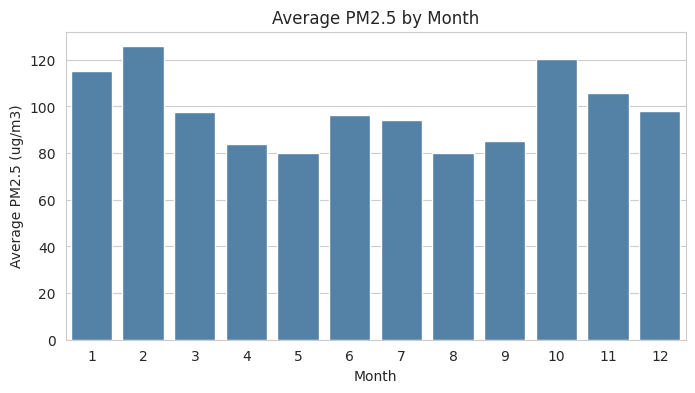

In [ ]:
monthly = df.groupby('month')['pm2.5'].mean()

plt.figure(figsize=(8, 4))
sns.barplot(x=monthly.index, y=monthly.values, color='steelblue')
plt.title('Average PM2.5 by Month')
plt.xlabel('Month')
plt.ylabel('Average PM2.5 (ug/m3)')
plt.show()

**Observation:** Pollution is highest in February, October and January (about 115 to 126) and lowest in May and August (about 80).

**Visualization 3: Average PM2.5 by Hour of Day**

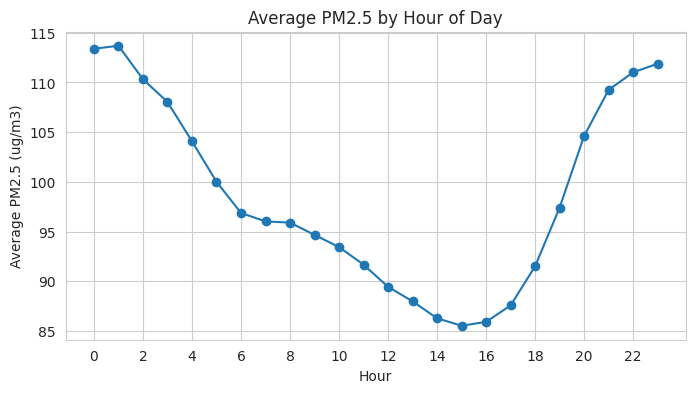

In [ ]:
hourly = df.groupby('hour')['pm2.5'].mean()

plt.figure(figsize=(8, 4))
plt.plot(hourly.index, hourly.values, marker='o')
plt.xticks(range(0, 24, 2))
plt.title('Average PM2.5 by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Average PM2.5 (ug/m3)')
plt.show()

**Observation:** Pollution is highest around midnight (about 113) and lowest around 3 to 4 PM (about 85).

**Visualization 4: Average PM2.5 by Year**

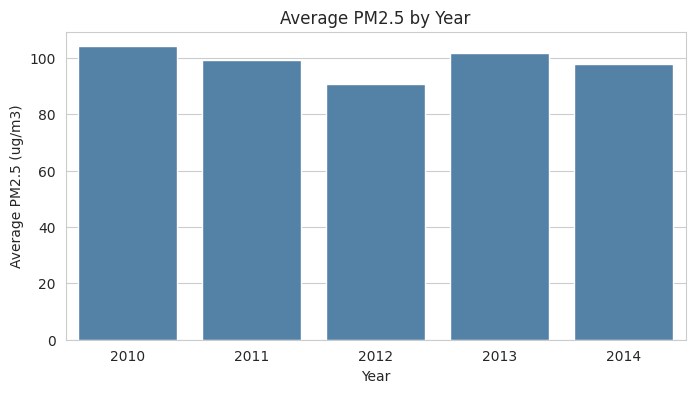

In [ ]:
yearly = df.groupby('year')['pm2.5'].mean()

plt.figure(figsize=(8, 4))
sns.barplot(x=yearly.index, y=yearly.values, color='steelblue')
plt.title('Average PM2.5 by Year')
plt.xlabel('Year')
plt.ylabel('Average PM2.5 (ug/m3)')
plt.show()

**Observation:** The yearly average stays between about 90 and 104, so there is no clear trend.

**Visualization 5: PM2.5 by Wind Direction**

       mean  median
cbwd               
NE     90.2    55.0
NW     70.1    31.0
SE    110.8    91.0
cv    126.2    98.0


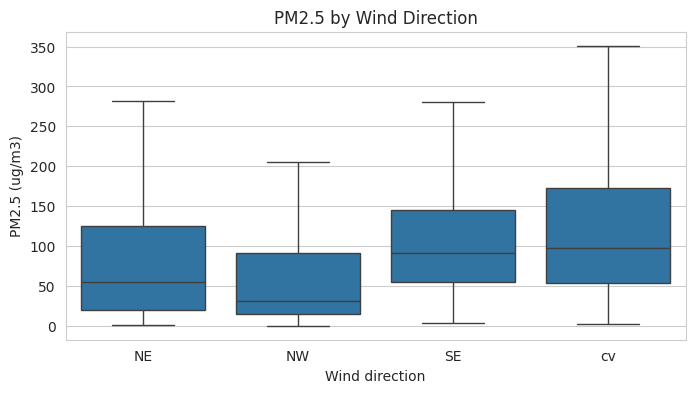

In [ ]:
# Visualization 5: PM2.5 by wind direction
print(df.groupby('cbwd')['pm2.5'].agg(['mean', 'median']).round(1))

plt.figure(figsize=(8, 4))
sns.boxplot(x='cbwd', y='pm2.5', data=df, order=['NE', 'NW', 'SE', 'cv'], showfliers=False)
plt.title('PM2.5 by Wind Direction')
plt.xlabel('Wind direction')
plt.ylabel('PM2.5 (ug/m3)')
plt.show()

**Observation:** NW wind gives the cleanest air (median 31); SE and cv winds give the dirtiest (median 91 and 98).

**Visualization 6: PM2.5 vs Wind Speed**

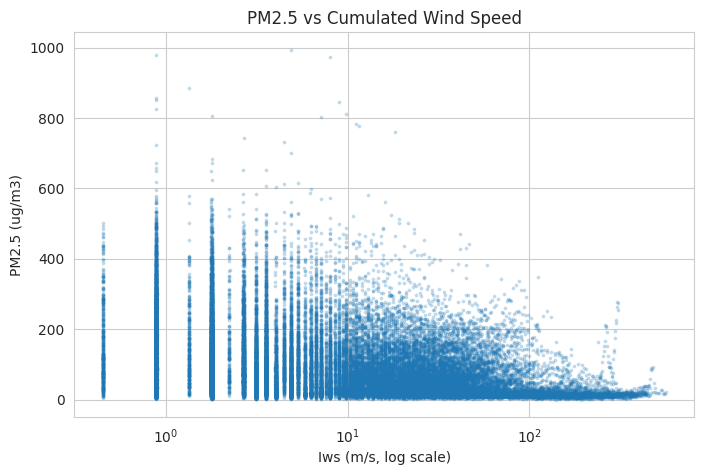

In [ ]:
# Visualization 6: PM2.5 vs cumulated wind speed (log scale on x)
plt.figure(figsize=(8, 5))
plt.scatter(df['Iws'], df['pm2.5'], s=3, alpha=0.2)
plt.xscale('log')
plt.title('PM2.5 vs Cumulated Wind Speed')
plt.xlabel('Iws (m/s, log scale)')
plt.ylabel('PM2.5 (ug/m3)')
plt.show()

**Observation:** High wind speed means low PM2.5; very high pollution happens only when wind speed is low.

**Visualization 7: PM2.5 vs Temperature**

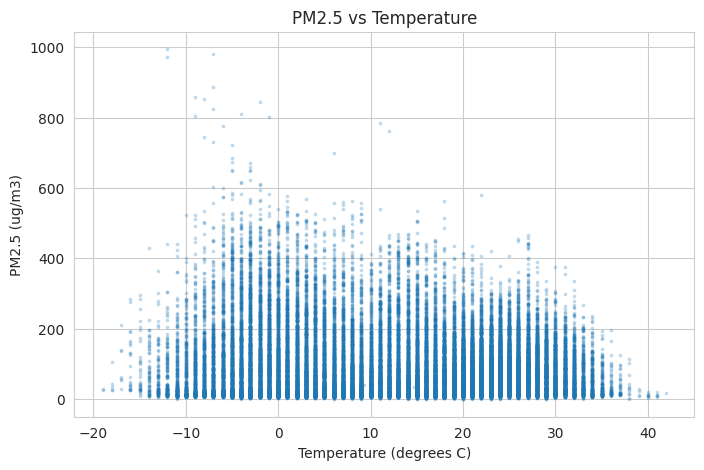

In [ ]:
# Visualization 7: PM2.5 vs temperature
plt.figure(figsize=(8, 5))
plt.scatter(df['TEMP'], df['pm2.5'], s=3, alpha=0.2)
plt.title('PM2.5 vs Temperature')
plt.xlabel('Temperature (degrees C)')
plt.ylabel('PM2.5 (ug/m3)')
plt.show()

**Observation:** The highest PM2.5 occurs in cold weather (about -12 to 0 degrees C); hot weather is mostly cleaner.

**Visualization 8: Autocorrelation of PM2.5**

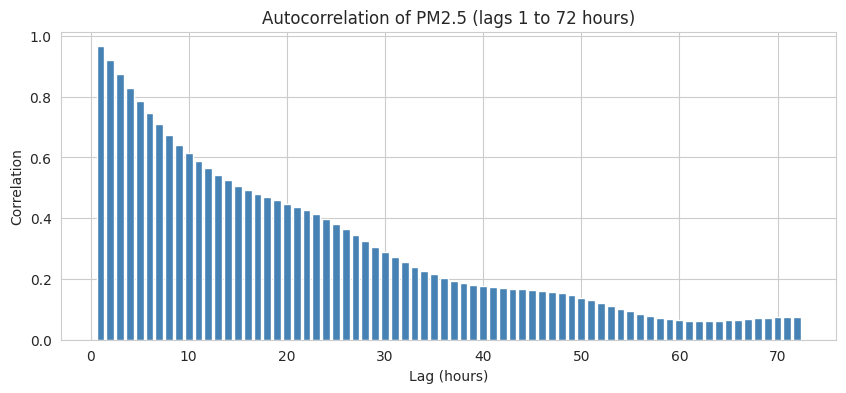

Lag 1 : 0.97
Lag 24: 0.4


In [ ]:
# Visualization 8: Autocorrelation of PM2.5 (how much past hours predict the present)
series = df['pm2.5']
lags = range(1, 73)
acf = [series.autocorr(lag=l) for l in lags]

plt.figure(figsize=(10, 4))
plt.bar(lags, acf, color='steelblue')
plt.title('Autocorrelation of PM2.5 (lags 1 to 72 hours)')
plt.xlabel('Lag (hours)')
plt.ylabel('Correlation')
plt.show()

print('Lag 1 :', round(acf[0], 2))
print('Lag 24:', round(acf[23], 2))

**Observation:** The previous hour is very strongly related to the current hour (0.97). The link falls to about 0.4 after 24 hours and to almost 0 after about 60 hours.

**Visualization 9: Missing PM2.5 Values per Year**

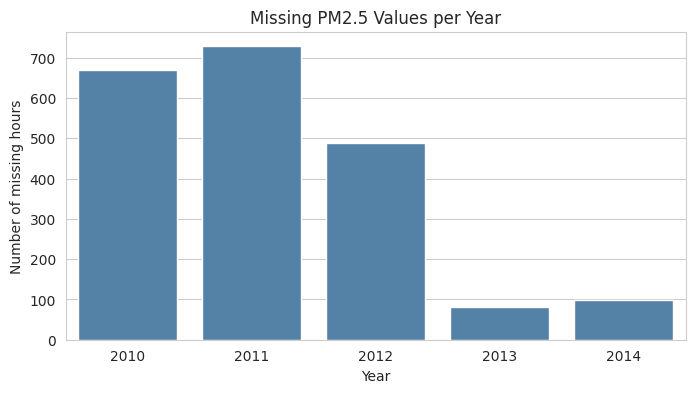

In [ ]:
# Visualization 9: Missing PM2.5 values per year
missing_year = df[df['pm2.5'].isnull()].groupby('year').size()

plt.figure(figsize=(8, 4))
sns.barplot(x=missing_year.index, y=missing_year.values, color='steelblue')
plt.title('Missing PM2.5 Values per Year')
plt.xlabel('Year')
plt.ylabel('Number of missing hours')
plt.show()

**Observation:** Most missing values are in 2010, 2011 and 2012 (about 670, 730 and 490); 2013 and 2014 have about 80 and 100.

**Visualization 10: Weather Feature Distributions**

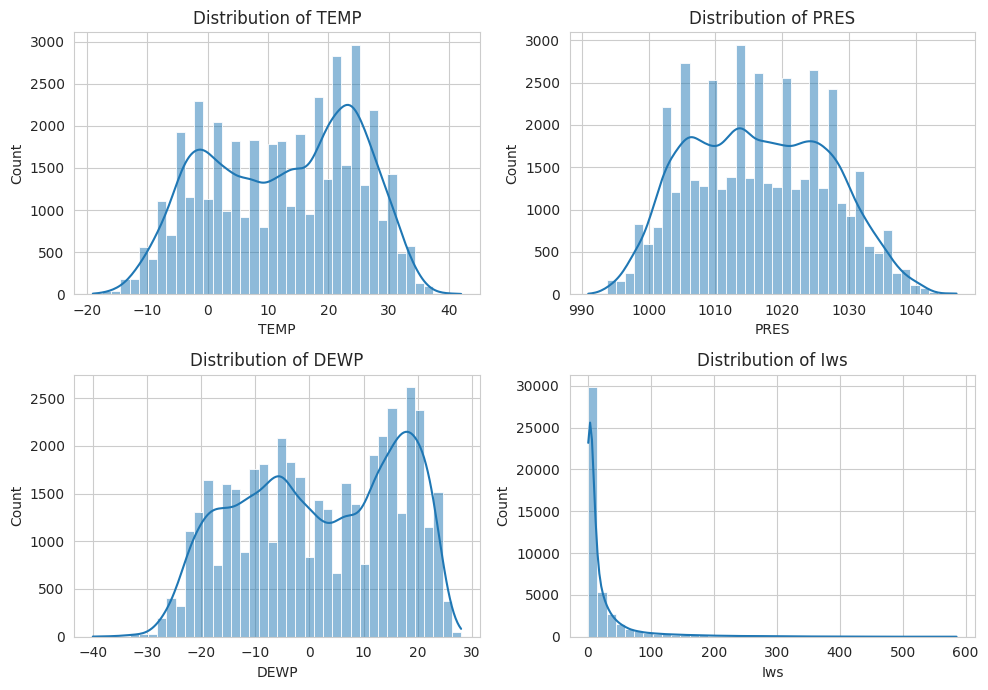

In [ ]:
# Visualization 10: Distribution of the weather features
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flatten(), ['TEMP', 'PRES', 'DEWP', 'Iws']):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title('Distribution of ' + col)
plt.tight_layout()
plt.show()

**Observation:** TEMP and DEWP have two peaks (cold and warm season); Iws is very skewed, with mostly small values.

### **3.8 Key EDA Insights**

* PM2.5 is right-skewed with many high spikes (about 4.2% of values are above 300), so outliers need careful treatment.
* 4.7% of PM2.5 values are missing, in 214 gaps. About 91% of the gaps are 24 hours or shorter, and most are in 2010 to 2012.
* Weather features alone have weak correlation with PM2.5. Wind speed and wind direction matter most, and their relationships are non-linear.
* PM2.5 has a clear pattern by hour of day and a moderate pattern by month, but no yearly trend.
* Past PM2.5 values (up to about one day) are strongly related to the present value, so lag features and LSTM/GRU sequences should help.
* DEWP, TEMP and PRES are highly correlated with each other, Iws is very skewed, and cbwd needs one-hot encoding.

---

## **4. Data Cleaning & Preprocessing**

Prepare the data so the models can learn from it.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

**4.1 Missing Value Treatment**

**Method used:** Linear interpolation estimates missing hourly PM2.5 values by drawing a straight line between the known reading before a gap and the known reading after it. We apply it only to gaps of 24 hours or less; longer gaps stay missing.

**Why limit the gap?** PM2.5 is strongly related to the previous hour, but the relationship weakens over longer periods. Interpolating a long gap could invent an unrealistic pollution pattern.

**Counts:** The `pm2.5` column has **2,067** missing values at the start. The code fills **702** and leaves **1,365** empty.

In [ ]:
# Find the size of each gap
is_na = df['pm2.5'].isnull()
gap_id = (is_na != is_na.shift()).cumsum()
gap_size = is_na.groupby(gap_id).transform('sum')

# Straight-line interpolation between known values before and after a gap
interp = df['pm2.5'].interpolate(method='linear', limit_area='inside')

# Fill only the short gaps (24 hours or less)
fill_mask = is_na & (gap_size <= 24) & interp.notnull()

# New column; the original pm2.5 stays unchanged
df['pm25_filled'] = df['pm2.5']
df.loc[fill_mask, 'pm25_filled'] = interp[fill_mask]

print('Missing before          :', df['pm2.5'].isnull().sum())
print('Filled (short gaps)     :', fill_mask.sum())
print('Still missing (long gaps):', df['pm25_filled'].isnull().sum())

Missing before          : 2067
Filled (short gaps)     : 702
Still missing (long gaps): 1365


**Observation:** The code filled 702 of the 2,067 original missing PM2.5 values. The remaining 1,365 values stay empty because they belong to long gaps or gaps at the edge where there is no known value on both sides. We preserve these as missing rather than inventing values.


**Check: one filled gap**

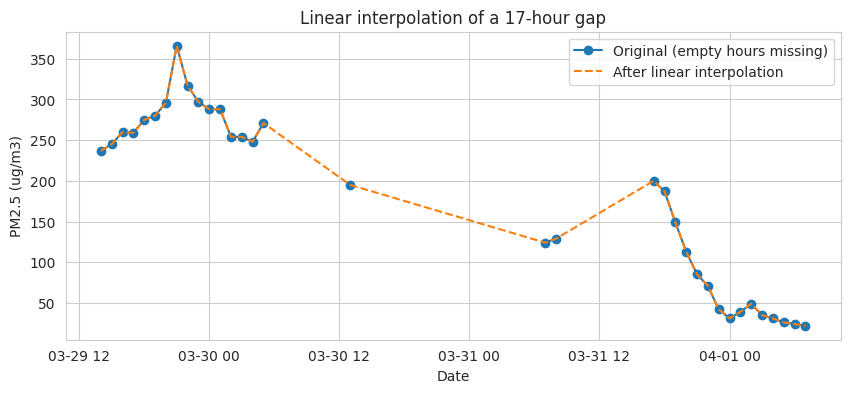

In [ ]:
import matplotlib.pyplot as plt

candidates = df.index[fill_mask & (gap_size >= 12)]
start = candidates[0]
gap_len = int(gap_size[start])
window = df.loc[start - 24 : start + gap_len + 24]

plt.figure(figsize=(10, 4))
plt.plot(window['datetime'], window['pm2.5'], 'o-', label='Original (empty hours missing)')
plt.plot(window['datetime'], window['pm25_filled'], '--', label='After linear interpolation')
plt.title(f'Linear interpolation of a {gap_len}-hour gap')
plt.xlabel('Date')
plt.ylabel('PM2.5 (ug/m3)')
plt.legend()
plt.show()

**Observation:** The dashed line joins the known values around a 17-hour gap. It follows the overall direction but cannot show changes inside the gap, so longer gaps are not filled.

**How the missing-value numbers connect (counts are hourly rows)**

| Step | Count | Meaning |
|---|---:|---|
| Missing PM2.5 values at the start | 2,067 | Original missing target values |
| Filled by linear interpolation | 702 | Missing values inside gaps of 24 hours or less |
| Still missing after interpolation | 1,365 | Not filled because gaps are too long or at a boundary |
| Rows removed before model training | 1,838 | A target or required lag is missing |
| Of these, target PM2.5 is missing | 1,365 | The row cannot be used as a target |
| Additional rows with a missing earlier-hour lag | 473 | The target exists, but a required lag is missing |

The counts are consistent: **2,067 − 702 = 1,365**, and **1,365 + 473 = 1,838**. These are different processing stages, so they should not be described as one single missing-value count.


**4.2 Duplicate Handling**

Check for repeated rows or hours, and that every row is exactly one hour after the previous one.

In [ ]:
# Duplicate rows
print('Duplicate rows       :', df.duplicated().sum())

# Duplicate timestamps (the same hour recorded twice)
print('Duplicate timestamps :', df['datetime'].duplicated().sum())

# Is every row exactly one hour after the previous one?
print(df['datetime'].diff().value_counts())

Duplicate rows       : 0
Duplicate timestamps : 0
datetime
0 days 01:00:00    43823
Name: count, dtype: int64


**Observation:** There are no duplicate rows or timestamps, and all 43,823 steps are exactly one hour, so the timeline is complete.

**4.3 Outlier Treatment**

Count outliers with the IQR rule (below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR).

In [ ]:
cols = ['pm25_filled', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
rows = []

for col in cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, round(low, 1), round(high, 1), n, round(n / len(df) * 100, 1)])

print(pd.DataFrame(rows, columns=['column', 'lower_fence', 'upper_fence', 'outliers', 'percent']))

        column  lower_fence  upper_fence  outliers  percent
0  pm25_filled       -133.0        299.0      1796      4.1
1         DEWP        -47.5         52.5         0      0.0
2         TEMP        -29.5         54.5         0      0.0
3         PRES        982.5       1050.5         0      0.0
4          Iws        -28.4         52.1      5101     11.6
5           Is          0.0          0.0       368      0.8
6           Ir          0.0          0.0      1808      4.1


**Observation:** `pm25_filled` has 1,796 outliers (4.1%, upper fence 299), `Iws` 5,101 (11.6%), `Is` 368 and `Ir` 1,808; `DEWP`, `TEMP` and `PRES` have none. **Decision:** all are kept, because the high PM2.5 values are real pollution episodes, not errors.

**4.4 Encoding**

**Method Used:** One-hot encoding of `cbwd` (the only text column) into four 0/1 columns.

**Justification:** The wind directions have no order, so numbers like 0, 1, 2, 3 would mislead the model.

In [ ]:
# One-hot encode wind direction into a new working table
df_model = pd.get_dummies(df, columns=['cbwd'], prefix='wind', dtype=int)

print(df_model.filter(like='wind_').head())
print(df_model.filter(like='wind_').sum())

   wind_NE  wind_NW  wind_SE  wind_cv
0        0        1        0        0
1        0        1        0        0
2        0        1        0        0
3        0        1        0        0
4        0        1        0        0
wind_NE     4997
wind_NW    14150
wind_SE    15290
wind_cv     9387
dtype: int64


**Observation:** `wind_NE`, `wind_NW`, `wind_SE` and `wind_cv` were created, and their totals match Section 3.3.

**4.5 Scaling / Normalization**

**Method Used:** MinMaxScaler (0 to 1), fitted on the training years (2010 to 2012) only.

**Justification:** The columns have very different ranges, and fitting on training data only stops information from the future leaking in. The target has its own scaler, to convert predictions back to ug/m3.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Training years: 2010 to 2012
train_mask = df_model['year'] <= 2012

# Scale the weather columns (the scaler learns min and max from training data only)
scale_cols = ['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir']
scaler = MinMaxScaler()
scaler.fit(df_model.loc[train_mask, scale_cols])

df_scaled = df_model.copy()
df_scaled[scale_cols] = scaler.transform(df_model[scale_cols])

# Scale the target with its own scaler (needed later to convert predictions back)
target_scaler = MinMaxScaler()
target_scaler.fit(df_model.loc[train_mask, ['pm25_filled']])
df_scaled['pm25_scaled'] = target_scaler.transform(df_model[['pm25_filled']])

# Check: training rows should range from 0 to 1
print(df_scaled.loc[train_mask, scale_cols + ['pm25_scaled']].agg(['min', 'max']).round(2))

     DEWP  TEMP  PRES  Iws   Is   Ir  pm25_scaled
min   0.0   0.0   0.0  0.0  0.0  0.0          0.0
max   1.0   1.0   1.0  1.0  1.0  1.0          1.0


**Observation:** In the training rows every column ranges from 0 to 1.

**Check: values outside 0 to 1**

In [ ]:
cols = scale_cols + ['pm25_scaled']
result = {}
for name, mask in [('Validation 2013', df_model['year'] == 2013),
                   ('Test 2014', df_model['year'] == 2014)]:
    part = df_scaled.loc[mask, cols]
    result[name] = ((part < 0) | (part > 1)).sum()

print(pd.DataFrame(result))

             Validation 2013  Test 2014
DEWP                      34         69
TEMP                       0          1
PRES                      13          0
Iws                        0          0
Is                         0          0
Ir                         0          0
pm25_scaled                0          0


**Observation:** After applying the scaler fitted on 2010–2012, some later weather readings fall outside 0 to 1: `DEWP` has 34 such values in 2013 and 69 in 2014; `PRES` has 13 in 2013; `TEMP` has 1 in 2014. The scaled target has none. This is expected when later data exceed the training minimum or maximum because `MinMaxScaler` does not automatically clip values. We keep these values and do not refit the scaler on validation/test data, because that would leak future information. The text wind-direction column was one-hot encoded before scaling and is not passed to this scaler.


**4.6 Project-Specific Preprocessing**

Drop the columns that are not needed (`No`, `day` and the original `pm2.5`) and keep the rows in time order.

In [ ]:
df_final = df_scaled.drop(columns=['No', 'day', 'pm2.5'])
df_final = df_final.sort_values('datetime').reset_index(drop=True)

print(df_final.shape)
print(list(df_final.columns))

(43824, 16)
['year', 'month', 'hour', 'DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'datetime', 'pm25_filled', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv', 'pm25_scaled']


**Observation:** The final table has 43,824 rows and 16 columns.

**4.7 Train / Validation / Test Split**

Split by whole years, in time order, without shuffling.

In [ ]:
train = df_final[df_final['year'] <= 2012]
val   = df_final[df_final['year'] == 2013]
test  = df_final[df_final['year'] == 2014]

for name, part in [('Training', train), ('Validation', val), ('Testing', test)]:
    print(name, part.shape, part['datetime'].min(), 'to', part['datetime'].max(),
          '| %:', round(len(part) / len(df_final) * 100, 1),
          '| missing pm25:', part['pm25_filled'].isnull().sum())

Training (26304, 16) 2010-01-01 00:00:00 to 2012-12-31 23:00:00 | %: 60.0 | missing pm25: 1365
Validation (8760, 16) 2013-01-01 00:00:00 to 2013-12-31 23:00:00 | %: 20.0 | missing pm25: 0
Testing (8760, 16) 2014-01-01 00:00:00 to 2014-12-31 23:00:00 | %: 20.0 | missing pm25: 0


**Training Size:** 26,304 rows (60%), 1 Jan 2010 to 31 Dec 2012

**Validation Size:** 8,760 rows (20%), all of 2013

**Testing Size:** 8,760 rows (20%), all of 2014

**Observation:** Every part has all seasons and no future data is used for training. All 1,365 remaining empty values are in the training part.

Save the splits and the scalers to Drive for the next phases.

In [ ]:
import joblib

# Save the splits
train.to_csv(BASE_DIR + '/data/processed/train.csv', index=False)
val.to_csv(BASE_DIR + '/data/processed/val.csv', index=False)
test.to_csv(BASE_DIR + '/data/processed/test.csv', index=False)

# Save the scalers (needed later to run the API)
joblib.dump(scaler, BASE_DIR + '/models/feature_scaler.pkl')
joblib.dump(target_scaler, BASE_DIR + '/models/target_scaler.pkl')

print('Saved to Drive')

Saved to Drive


Check the project folder.

In [ ]:
print(BASE_DIR)
for root, dirs, files in os.walk(BASE_DIR):
    print(root.replace(BASE_DIR, '.'), files)

/content/drive/MyDrive/beijing-pm25-prediction
. []
./data []
./data/raw ['PRSA_data_2010.1.1-2014.12.31.csv']
./data/processed ['val.csv', 'test.csv', 'train.csv', 'sequences.npz', 'val_features.csv', 'train_features.csv', 'feature_cols.json', 'test_features.csv']
./notebooks ['Beijing_PM25_Project_Phase1.ipynb', 'Beijing_PM25_Project_moreExplanation.ipynb', 'Phase2_Beijing_PM25_Project.ipynb', 'Beijing_PM25_Project_Copy.ipynb', 'Beijing_PM25_Project.ipynb']
./models ['random_forest.pkl', 'model_metadata.json', 'lstm_model.keras', 'rf_selected_features.json', 'gru_model.keras', 'feature_scaler.pkl', 'target_scaler.pkl']
./reports ['test_model_comparison.csv']
./reports/figures ['test_actual_vs_predicted.png']
./app []


## **PHASE 2 – FEATURE EXTRACTION & MODEL BUILDING**

Start from the files saved in Phase 1.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/beijing-pm25-prediction'
print('Project folder found:', os.path.exists(BASE_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder found: True


Load the saved files. Seed 42 makes the results repeatable.

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)   # fixed seed, so results can be repeated

# Load the files saved in Phase 1
train = pd.read_csv(BASE_DIR + '/data/processed/train.csv', parse_dates=['datetime'])
val   = pd.read_csv(BASE_DIR + '/data/processed/val.csv',   parse_dates=['datetime'])
test  = pd.read_csv(BASE_DIR + '/data/processed/test.csv',  parse_dates=['datetime'])

print(train.shape, val.shape, test.shape)
print('Missing pm25 in train:', train['pm25_filled'].isnull().sum())

(26304, 16) (8760, 16) (8760, 16)
Missing pm25 in train: 1365


## **5. Feature Engineering / Representation**

### **5.1 Feature Engineering**

**Cyclical time features:** hour and month are placed on a circle (sine and cosine), so 23:00 is close to 00:00 and December is close to January.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
# Put hour and month on a circle, so 23:00 is close to 00:00 and December is close to January
def add_cyclic(df):
    df = df.copy()
    df['hour_sin']  = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos']  = np.cos(2 * np.pi * df['hour'] / 24)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    return df

train = add_cyclic(train)
val   = add_cyclic(val)
test  = add_cyclic(test)

# Check a few hours
print(train[['hour', 'hour_sin', 'hour_cos']].drop_duplicates().head(24).round(2).iloc[[0, 6, 12, 18, 23]])
print(train.shape)

    hour  hour_sin  hour_cos
0      0      0.00      1.00
6      6      1.00      0.00
12    12      0.00     -1.00
18    18     -1.00     -0.00
23    23     -0.26      0.97
(26304, 20)


**Observation:** Four columns were added (`hour_sin`, `hour_cos`, `month_sin`, `month_cos`); the training table now has 20 columns (table columns, not the model features).

**Lag features:** PM2.5 from 1, 2, 3, 6, 12 and 24 hours ago (the previous hour correlates 0.97 with the current hour).

In [ ]:
# Join the three parts back in time order, so lags can look across the year boundaries
full = pd.concat([train, val, test]).sort_values('datetime').reset_index(drop=True)

# PM2.5 (scaled) from 1, 2, 3, 6, 12 and 24 hours ago
lags = [1, 2, 3, 6, 12, 24]
for lag in lags:
    full[f'pm25_lag{lag}'] = full['pm25_scaled'].shift(lag)

print(full.shape)
print(full.loc[[1000, 1001, 1002], ['datetime', 'pm25_scaled', 'pm25_lag1']])

lag_cols = ['pm25_scaled'] + [f'pm25_lag{l}' for l in lags]
print('Rows with an empty target or lag:', full[lag_cols].isnull().any(axis=1).sum())

(43824, 26)
                datetime  pm25_scaled  pm25_lag1
1000 2010-02-11 16:00:00     0.018109   0.013078
1001 2010-02-11 17:00:00     0.017103   0.018109
1002 2010-02-11 18:00:00     0.019115   0.017103
Rows with an empty target or lag: 1838


**Observation:** 1,838 rows (4.2%) have an empty target or lag because of the long gaps, and they are removed before training. Interpolated values are part of the target and the lag inputs; the check at the end of Section 9 compares scores on all hours and on observed-only hours.


**Split back by year and remove the empty rows.**

In [ ]:
# Split back by year and remove rows with an empty target or lag
train_f = full[full['year'] <= 2012].dropna(subset=lag_cols)
val_f   = full[full['year'] == 2013].dropna(subset=lag_cols)
test_f  = full[full['year'] == 2014].dropna(subset=lag_cols)

print(train_f.shape, val_f.shape, test_f.shape)
print('Total rows left:', len(train_f) + len(val_f) + len(test_f))

(24466, 26) (8760, 26) (8760, 26)
Total rows left: 41986


**Observation:** Training has 24,466 rows, validation 8,760 and test 8,760 (41,986 in total).

**Previous-hour weather:** the weather of the previous hour is added, so only information known before the predicted hour is used.

In [ ]:
# Weather of the previous hour (a forecast cannot use the current hour's weather)
weather_cols = ['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir',
                'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv']
for col in weather_cols:
    full[col + '_prev'] = full[col].shift(1)

# Split again by year and remove rows with an empty target or lag
train_f = full[full['year'] <= 2012].dropna(subset=lag_cols)
val_f   = full[full['year'] == 2013].dropna(subset=lag_cols)
test_f  = full[full['year'] == 2014].dropna(subset=lag_cols)

print(train_f.shape, val_f.shape, test_f.shape)

(24466, 36) (8760, 36) (8760, 36)


**Observation:** 10 weather columns were added; the tables now have 36 columns.

**Summary of 5.1:** sine and cosine of hour and month, PM2.5 lags (1, 2, 3, 6, 12, 24 hours) and the previous-hour weather.

### **5.2 Feature Extraction / Representation**

**Correlation-based selection:** check how strongly each feature is related to PM2.5.

In [ ]:
# All features the ML models can use
feature_cols = [f'pm25_lag{l}' for l in lags] \
             + [c + '_prev' for c in weather_cols] \
             + ['hour_sin', 'hour_cos', 'month_sin', 'month_cos']

# Correlation of each feature with the target (training years only)
corr = train_f[feature_cols + ['pm25_scaled']].corr()['pm25_scaled'].drop('pm25_scaled')
print(corr.sort_values(ascending=False).round(2))

pm25_lag1       0.96
pm25_lag2       0.91
pm25_lag3       0.86
pm25_lag6       0.73
pm25_lag12      0.55
pm25_lag24      0.39
DEWP_prev       0.25
wind_cv_prev    0.18
wind_SE_prev    0.14
hour_cos        0.09
month_cos       0.04
hour_sin        0.03
Is_prev         0.01
TEMP_prev       0.01
wind_NE_prev   -0.03
Ir_prev        -0.06
month_sin      -0.06
PRES_prev      -0.14
Iws_prev       -0.26
wind_NW_prev   -0.28
Name: pm25_scaled, dtype: float64


**Observation:** The lag features are strongest (lag 1: 0.96). The best weather features are `wind_NW_prev` (-0.28), `Iws_prev` (-0.26) and `DEWP_prev` (0.25).

**SelectKBest** (scikit-learn) uses an F-test to score each feature individually against the target. Here, `p_value < 0.05` is the chosen screening rule for a statistically detectable univariate association. It does **not** prove causation or guarantee that a feature is useful in every model.


In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

X_train = train_f[feature_cols]
y_train = train_f['pm25_scaled']

# k='all' gives a score to every feature without removing any yet
selector = SelectKBest(score_func=f_regression, k='all').fit(X_train, y_train)

scores = pd.DataFrame({'score': selector.scores_.round(0),
                       'p_value': selector.pvalues_.round(3)},
                      index=feature_cols).sort_values('score', ascending=False)
print(scores)

                 score  p_value
pm25_lag1     301121.0    0.000
pm25_lag2     116945.0    0.000
pm25_lag3      68962.0    0.000
pm25_lag6      27473.0    0.000
pm25_lag12     10498.0    0.000
pm25_lag24      4436.0    0.000
wind_NW_prev    2118.0    0.000
Iws_prev        1817.0    0.000
DEWP_prev       1583.0    0.000
wind_cv_prev     857.0    0.000
wind_SE_prev     519.0    0.000
PRES_prev        484.0    0.000
hour_cos         186.0    0.000
month_sin         94.0    0.000
Ir_prev           80.0    0.000
month_cos         41.0    0.000
hour_sin          19.0    0.000
wind_NE_prev      18.0    0.000
Is_prev            3.0    0.072
TEMP_prev          1.0    0.307


**Observation:** Lag 1 scores highest, and 18 of the 20 features have a p-value below 0.05.

In [ ]:
selector = SelectKBest(score_func=f_regression, k=18).fit(X_train, y_train)
selected = list(X_train.columns[selector.get_support()])

print('Selected:', len(selected))
print('Removed :', [c for c in feature_cols if c not in selected])

Selected: 18
Removed : ['TEMP_prev', 'Is_prev']


**Decision:** We set **K = 18**, keeping 18 of the 20 candidate features. In this training-set F-test, `TEMP_prev` (p = 0.307) and `Is_prev` (p = 0.072) are above the 0.05 threshold, so they are excluded from the Random Forest feature list. This is a feature-screening decision, not proof that those variables can never matter. The LSTM and GRU use the separate 24-hour sequence inputs described below.

**24-hour sequences for LSTM and GRU:**

* Each sample is the last 24 hours (15 values per hour: PM2.5, the weather columns and the sine and cosine of hour and month).
* The answer is the PM2.5 of the **next hour**.

**Same steps for training and prediction:**

* A new prediction takes the previous 24 hours.
* They are scaled with the saved scalers.
* The column order stays the same (`seq_cols`).
* The answer is converted back to ug/m3 with `target_scaler`.
* The Random Forest uses the PM2.5 lags (1, 2, 3, 6, 12, 24 hours), the previous-hour weather and the hour and month sine and cosine, in the order of `selected`.

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view

window = 24     # use the last 24 hours
seq_cols = ['pm25_scaled'] + weather_cols + ['hour_sin', 'hour_cos', 'month_sin', 'month_cos']

values = full[seq_cols].values
target = full['pm25_scaled'].values
dates  = full['datetime'].values

# Every block of 24 hours, and the hour that comes right after it
blocks = sliding_window_view(values, (window, len(seq_cols)))[:, 0]
X_all  = blocks[:-1]
y_all  = target[window:]
d_all  = pd.to_datetime(dates[window:])

# Keep only complete blocks (no empty values)
ok = ~np.isnan(X_all).any(axis=(1, 2)) & ~np.isnan(y_all)
X_all, y_all, d_all = X_all[ok], y_all[ok], d_all[ok]

# Split by the year of the hour being predicted
tr, va, te = d_all.year <= 2012, d_all.year == 2013, d_all.year == 2014
X_train_seq, y_train_seq = X_all[tr], y_all[tr]
X_val_seq,   y_val_seq   = X_all[va], y_all[va]
X_test_seq,  y_test_seq  = X_all[te], y_all[te]

print(X_train_seq.shape, X_val_seq.shape, X_test_seq.shape)

(24466, 24, 15) (8760, 24, 15) (8760, 24, 15)


**Observation:** The shapes are (24,466, 24, 15) for training and (8,760, 24, 15) for validation and test: the same hours as the ML tables, so the comparison is fair.

Save the features and the 24-hour blocks to Drive.

In [ ]:
import json

# 24-hour blocks for LSTM and GRU
np.savez_compressed(BASE_DIR + '/data/processed/sequences.npz',
                    X_train=X_train_seq, y_train=y_train_seq,
                    X_val=X_val_seq,     y_val=y_val_seq,
                    X_test=X_test_seq,   y_test=y_test_seq)

# Tables for the ML models, and the list of feature names
train_f.to_csv(BASE_DIR + '/data/processed/train_features.csv', index=False)
val_f.to_csv(BASE_DIR + '/data/processed/val_features.csv', index=False)
test_f.to_csv(BASE_DIR + '/data/processed/test_features.csv', index=False)
json.dump(feature_cols, open(BASE_DIR + '/data/processed/feature_cols.json', 'w'))

print('Saved to Drive')

Saved to Drive


**Summary of 5.2:**

* SelectKBest scored the **20 candidate features** and kept the **best 18** (`selected`).
* `TEMP_prev` and `Is_prev` are removed.
* The Random Forest uses these same 18 features in training, validation and test.
* The LSTM and GRU use the 24-hour sequences (15 values per hour).

## **6. Model Building**

**6.1 Baseline Model: same as last hour**

The baseline predicts that the next hour equals the last hour. Scores: **MAE** (average error, smaller is better), **RMSE** (like MAE but big errors count more) and **R2** (1.0 is perfect). All models are scored on the validation year 2013.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_scaler = joblib.load(BASE_DIR + '/models/target_scaler.pkl')

def to_real(x):
    # scaled 0-1 value -> real ug/m3
    return target_scaler.inverse_transform(np.array(x).reshape(-1, 1)).ravel()

def evaluate(y_true_scaled, y_pred_scaled):
    # MAE, RMSE and R2 on the real ug/m3 scale
    y_true, y_pred = to_real(y_true_scaled), to_real(y_pred_scaled)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return round(mae, 2), round(rmse, 2), round(r2_score(y_true, y_pred), 3)

# Baseline: predict "same as last hour"
print('Baseline (MAE, RMSE, R2), validation 2013:',
      evaluate(val_f['pm25_scaled'], val_f['pm25_lag1']))

Baseline (MAE, RMSE, R2), validation 2013: (13.08, np.float64(24.69), 0.936)


**Observation:** MAE 13.08, RMSE 24.69 and R2 0.936. It is a strong benchmark that the other models must beat.

**6.2 Model 1: Random Forest** (scikit-learn)

Many decision trees whose answers are averaged. It can learn non-linear patterns.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:

rf = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5,
                           random_state=42, n_jobs=-1)
rf.fit(train_f[selected], train_f['pm25_scaled'])

rf_pred = rf.predict(val_f[selected])
print('Random Forest (MAE, RMSE, R2), validation 2013:', evaluate(val_f['pm25_scaled'], rf_pred))

importance = pd.Series(rf.feature_importances_, index=selected).sort_values(ascending=False)
print(importance.head(5).round(3))

Random Forest (MAE, RMSE, R2), validation 2013: (12.97, np.float64(25.23), 0.934)
pm25_lag1     0.968
pm25_lag2     0.008
pm25_lag3     0.003
pm25_lag6     0.003
pm25_lag12    0.003
dtype: float64


**Observation:** Random Forest (100 trees, max depth 12, 18 features): MAE 12.97, RMSE 25.23, R2 0.934, almost the same as the baseline. `pm25_lag1` gives 96.8% of the decisions, so the model mostly copies the last hour.

**6.3 Model 2: LSTM** (TensorFlow / Keras)

Reads the last 24 hours in order and remembers what matters. 64 units, dropout 0.2 (switches off some units while learning, so the model does not memorise), Adam optimizer.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)   # fixed seed, so results can be repeated

lstm_model = keras.Sequential([
    layers.Input(shape=(24, 15)),   # 24 hours, 15 values per hour
    layers.LSTM(64),                # reads the sequence
    layers.Dropout(0.2),            # avoids memorising
    layers.Dense(1)                 # the predicted PM2.5 (scaled)
])

lstm_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse')
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

**Observation:** The model has 20,545 trainable parameters.

Reload the saved data (needed only after a Colab restart).

In [ ]:
import json, joblib
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/beijing-pm25-prediction'
P = BASE_DIR + '/data/processed/'

# Feature tables and feature names (ML models)
train_f = pd.read_csv(P + 'train_features.csv', parse_dates=['datetime'])
val_f   = pd.read_csv(P + 'val_features.csv',   parse_dates=['datetime'])
test_f  = pd.read_csv(P + 'test_features.csv',  parse_dates=['datetime'])
feature_cols = json.load(open(P + 'feature_cols.json'))

# 24-hour blocks (LSTM and GRU)
seq = np.load(P + 'sequences.npz')
X_train_seq, y_train_seq = seq['X_train'], seq['y_train']
X_val_seq,   y_val_seq   = seq['X_val'],   seq['y_val']
X_test_seq,  y_test_seq  = seq['X_test'],  seq['y_test']

# Scaler and the evaluation helper
target_scaler = joblib.load(BASE_DIR + '/models/target_scaler.pkl')

def to_real(x):
    return target_scaler.inverse_transform(np.array(x).reshape(-1, 1)).ravel()

def evaluate(y_true_scaled, y_pred_scaled):
    y_true, y_pred = to_real(y_true_scaled), to_real(y_pred_scaled)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return round(mae, 2), round(rmse, 2), round(r2_score(y_true, y_pred), 3)

print(train_f.shape, val_f.shape, X_train_seq.shape, X_val_seq.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(24466, 36) (8760, 36) (24466, 24, 15) (8760, 24, 15)


Train the LSTM. Early stopping ends the training when the validation loss stops improving.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)   # fixed seed, so results can be repeated

# Model: 24 hours x 15 values -> LSTM -> Dropout -> 1 output
lstm_model = keras.Sequential([
    layers.Input(shape=(24, 15)),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(1)
])
lstm_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse')

# Training: stop early if validation loss does not improve for 4 rounds
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                           restore_best_weights=True)

history_lstm = lstm_model.fit(X_train_seq, y_train_seq,
                              validation_data=(X_val_seq, y_val_seq),
                              epochs=20, batch_size=128,
                              callbacks=[early_stop], verbose=2)

lstm_pred = lstm_model.predict(X_val_seq, verbose=0).ravel()
print('LSTM (MAE, RMSE, R2), validation 2013:', evaluate(y_val_seq, lstm_pred))

Epoch 1/20
192/192 - 6s - 30ms/step - loss: 0.0079 - val_loss: 0.0019
Epoch 2/20
192/192 - 1s - 7ms/step - loss: 0.0024 - val_loss: 0.0014
Epoch 3/20
192/192 - 1s - 6ms/step - loss: 0.0017 - val_loss: 0.0012
Epoch 4/20
192/192 - 1s - 7ms/step - loss: 0.0014 - val_loss: 0.0011
Epoch 5/20
192/192 - 1s - 7ms/step - loss: 0.0012 - val_loss: 0.0010
Epoch 6/20
192/192 - 1s - 6ms/step - loss: 0.0010 - val_loss: 8.4960e-04
Epoch 7/20
192/192 - 1s - 6ms/step - loss: 8.9131e-04 - val_loss: 7.7396e-04
Epoch 8/20
192/192 - 1s - 6ms/step - loss: 8.1484e-04 - val_loss: 6.8170e-04
Epoch 9/20
192/192 - 1s - 6ms/step - loss: 7.4067e-04 - val_loss: 7.0455e-04
Epoch 10/20
192/192 - 1s - 7ms/step - loss: 7.1679e-04 - val_loss: 6.2427e-04
Epoch 11/20
192/192 - 1s - 6ms/step - loss: 6.9608e-04 - val_loss: 6.8299e-04
Epoch 12/20
192/192 - 1s - 7ms/step - loss: 6.5891e-04 - val_loss: 6.2927e-04
Epoch 13/20
192/192 - 1s - 6ms/step - loss: 6.4798e-04 - val_loss: 6.2999e-04
Epoch 14/20
192/192 - 1s - 6ms/step - 

**Observation:** Validation 2013: MAE 15.35, RMSE 24.84, R2 0.936. Training stopped at epoch 14 (best epoch 10), and training and validation loss stayed close, so there is no overfitting. It matches the baseline in RMSE and R2 but is worse in MAE.

**6.4 Model 3: GRU** (TensorFlow / Keras)

A lighter version of the LSTM with fewer parameters (15,617), trained in the same way.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

# Same design as the LSTM, but with a GRU layer
gru_model = keras.Sequential([
    layers.Input(shape=(24, 15)),
    layers.GRU(64),
    layers.Dropout(0.2),
    layers.Dense(1)
])
gru_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse')
gru_model.summary()

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                           restore_best_weights=True)

history_gru = gru_model.fit(X_train_seq, y_train_seq,
                            validation_data=(X_val_seq, y_val_seq),
                            epochs=20, batch_size=128,
                            callbacks=[early_stop], verbose=2)

gru_pred = gru_model.predict(X_val_seq, verbose=0).ravel()
print('GRU (MAE, RMSE, R2), validation 2013:', evaluate(y_val_seq, gru_pred))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        15,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,617 (61.00 KB)

 Trainable params: 15,617 (61.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
192/192 - 2s - 12ms/step - loss: 0.0132 - val_loss: 0.0015
Epoch 2/20
192/192 - 1s - 7ms/step - loss: 0.0030 - val_loss: 0.0011
Epoch 3/20
192/192 - 1s - 6ms/step - loss: 0.0018 - val_loss: 9.5819e-04
Epoch 4/20
192/192 - 1s - 7ms/step - loss: 0.0013 - val_loss: 8.4801e-04
Epoch 5/20
192/192 - 1s - 6ms/step - loss: 0.0011 - val_loss: 7.4886e-04
Epoch 6/20
192/192 - 1s - 6ms/step - loss: 9.5261e-04 - val_loss: 6.9763e-04
Epoch 7/20
192/192 - 1s - 6ms/step - loss: 8.6452e-04 - val_loss: 6.9206e-04
Epoch 8/20
192/192 - 1s - 6ms/step - loss: 7.9472e-04 - val_loss: 6.4523e-04
Epoch 9/20
192/192 - 1s - 7ms/step - loss: 7.3775e-04 - val_loss: 6.7473e-04
Epoch 10/20
192/192 - 1s - 6ms/step - loss: 7.2221e-04 - val_loss: 6.6496e-04
Epoch 11/20
192/192 - 1s - 6ms/step - loss: 7.0572e-04 - val_loss: 6.7776e-04
Epoch 12/20
192/192 - 1s - 7ms/step - loss: 6.7360e-04 - val_loss: 6.2261e-04
Epoch 13/20
192/192 - 1s - 6ms/step - loss: 6.5749e-04 - val_loss: 6.1468e-04
Epoch 14/20
192/192 - 

**Observation:** Validation 2013: MAE 15.23, RMSE 24.58, R2 0.937. It is marginally the best in RMSE and R2, but all four models are very close.

**6.5 Model Architecture**

| Setting | Random Forest | LSTM | GRU |
|---|---|---|---|
| Input | 18 features of one hour | 24 hours x 15 values | 24 hours x 15 values |
| Main layer | 100 trees, max depth 12, min 5 samples per leaf | LSTM, 64 units | GRU, 64 units |
| Dropout | not applicable | 0.2 | 0.2 |
| Output | 1 number | Dense(1), linear | Dense(1), linear |
| Activation | not applicable | tanh and sigmoid inside the layer, linear output | tanh and sigmoid inside the layer, linear output |
| Loss | squared error | MSE | MSE |
| Optimizer / learning rate | not applicable | Adam, 0.001 | Adam, 0.001 |
| Batch size / epochs | not applicable | 128 / up to 20, early stopping (patience 4) | 128 / up to 20, early stopping (patience 4) |
| Parameters | not applicable | 20,545 | 15,617 |
| Random seed | 42 | 42 | 42 |

**Summary of Section 6: validation results (2013)**

| Model | MAE | RMSE | R2 |
|---|---|---|---|
| Baseline (same as last hour) | 13.08 | 24.69 | 0.936 |
| Random Forest | 12.97 | 25.23 | 0.934 |
| LSTM | 15.35 | 24.84 | 0.936 |
| GRU | 15.23 | 24.58 | 0.937 |

All four models reach an R2 of about 0.93 to 0.94, because the previous hour already explains most of the next hour. The GRU is marginally best in RMSE and R2; the baseline and the Random Forest are best in MAE.

**Planned in Phase 3:** predict the change from the last hour, test a longer forecast horizon, and evaluate on the test year 2014.

**Prediction Example: actual vs predicted (first week of 2013)**

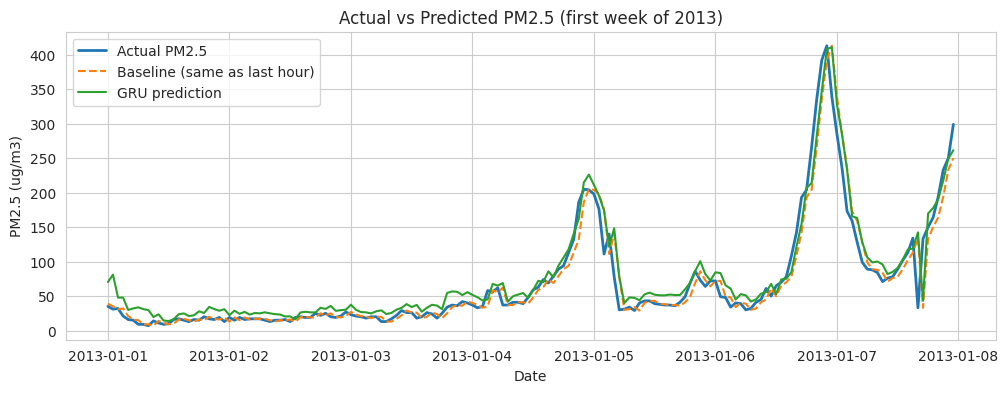

In [ ]:
import matplotlib.pyplot as plt

# First 7 days (168 hours) of 2013: actual vs predicted
n = 168
hours  = val_f['datetime'].values[:n]
actual = to_real(y_val_seq[:n])
base   = to_real(val_f['pm25_lag1'].values[:n])

plt.figure(figsize=(12, 4))
plt.plot(hours, actual, label='Actual PM2.5', linewidth=2)
plt.plot(hours, base, label='Baseline (same as last hour)', linestyle='--')

# The GRU line appears only if the GRU cell has been run in this session
if 'gru_pred' in globals():
    plt.plot(hours, to_real(gru_pred[:n]), label='GRU prediction')
else:
    print('Run the GRU cell first to add the GRU line to this chart.')

plt.title('Actual vs Predicted PM2.5 (first week of 2013)')
plt.xlabel('Date')
plt.ylabel('PM2.5 (ug/m3)')
plt.legend()
plt.show()

**Observation:** The baseline and the GRU both follow the real PM2.5 closely, including the big rise on 6 and 7 January. The baseline lags the real line by one hour; the GRU is slightly too high when pollution is low and misses part of the sharp rise at the end.

<font color="197AA6" size=5px><b>PHASE 3 – MODEL TRAINING & MODEL EVALUATION</b></font>

Load the saved Phase 2 files (run this cell first after a Colab restart).

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
import json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers

drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/beijing-pm25-prediction'
P = BASE_DIR + '/data/processed/'

# ML tables, feature names and the 24-hour blocks saved in Section 5
train_f = pd.read_csv(P + 'train_features.csv', parse_dates=['datetime'])
val_f   = pd.read_csv(P + 'val_features.csv',   parse_dates=['datetime'])
test_f  = pd.read_csv(P + 'test_features.csv',  parse_dates=['datetime'])
feature_cols = json.load(open(P + 'feature_cols.json'))
selected = [c for c in feature_cols if c not in ['TEMP_prev', 'Is_prev']]   # K = 18 (Section 5.2)

seq = np.load(P + 'sequences.npz')
X_train_seq, y_train_seq = seq['X_train'], seq['y_train']
X_val_seq,   y_val_seq   = seq['X_val'],   seq['y_val']
X_test_seq,  y_test_seq  = seq['X_test'],  seq['y_test']

# Scaler and the scoring helper (MAE, RMSE, R2 in real ug/m3)
target_scaler = joblib.load(BASE_DIR + '/models/target_scaler.pkl')

def to_real(x):
    return target_scaler.inverse_transform(np.array(x).reshape(-1, 1)).ravel()

def evaluate(y_true_scaled, y_pred_scaled):
    y_true, y_pred = to_real(y_true_scaled), to_real(y_pred_scaled)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    return round(mae, 2), round(rmse, 2), round(r2_score(y_true, y_pred), 3)

# Check: the ML tables and the 24-hour blocks describe the same hours
for table, y_seq, X_seq in [(train_f, y_train_seq, X_train_seq), (val_f, y_val_seq, X_val_seq), (test_f, y_test_seq, X_test_seq)]:
    assert np.allclose(table['pm25_scaled'].values, y_seq)
    assert np.allclose(table['pm25_lag1'].values, X_seq[:, -1, 0])
print('Loaded and aligned:', train_f.shape, val_f.shape, test_f.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded and aligned: (24466, 36) (8760, 36) (8760, 36)


## **7. Model Training**

### **7.1 Model Training**

The LSTM and GRU are trained as in Phase 2, now also tracking MAE for the graphs. The Random Forest uses the 18 selected features. Early stopping ends the training when the validation loss stops improving.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
def build_model(kind, units=64, dropout=0.2, lr=0.001):
    keras.utils.set_random_seed(42)   # fixed seed, so results can be repeated
    rnn = layers.LSTM(units) if kind == 'LSTM' else layers.GRU(units)
    model = keras.Sequential([layers.Input(shape=(24, 15)), rnn,
                              layers.Dropout(dropout), layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    return model

def train_model(model, y_tr=None, y_va=None):
    y_tr = y_train_seq if y_tr is None else y_tr
    y_va = y_val_seq if y_va is None else y_va
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    return model.fit(X_train_seq, y_tr, validation_data=(X_val_seq, y_va),
                     epochs=20, batch_size=128, callbacks=[stop], verbose=0)

# Deep learning models
lstm_model = build_model('LSTM'); hist_lstm = train_model(lstm_model)
gru_model  = build_model('GRU');  hist_gru  = train_model(gru_model)

# Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(train_f[selected], train_f['pm25_scaled'])

# Predictions (scaled 0-1) for validation 2013 and test 2014
preds_val = {'Baseline': val_f['pm25_lag1'].values,
             'Random Forest': rf.predict(val_f[selected]),
             'LSTM': lstm_model.predict(X_val_seq, verbose=0).ravel(),
             'GRU': gru_model.predict(X_val_seq, verbose=0).ravel()}
preds_test = {'Baseline': test_f['pm25_lag1'].values,
              'Random Forest': rf.predict(test_f[selected]),
              'LSTM': lstm_model.predict(X_test_seq, verbose=0).ravel(),
              'GRU': gru_model.predict(X_test_seq, verbose=0).ravel()}

print('LSTM stopped after', len(hist_lstm.history['loss']), 'epochs | GRU stopped after', len(hist_gru.history['loss']), 'epochs')
for name in preds_val:
    print(name, '- validation (MAE, RMSE, R2):', evaluate(val_f['pm25_scaled'], preds_val[name]))

LSTM stopped after 14 epochs | GRU stopped after 18 epochs
Baseline - validation (MAE, RMSE, R2): (13.08, 24.69, 0.936)
Random Forest - validation (MAE, RMSE, R2): (12.97, 25.23, 0.934)
LSTM - validation (MAE, RMSE, R2): (15.35, 24.84, 0.936)
GRU - validation (MAE, RMSE, R2): (15.23, 24.58, 0.937)


### **7.2 Training / Validation MAE**

This is a regression task, so classification accuracy is not the right metric. The graph shows MAE (mean absolute error) for training and validation; lower is better.


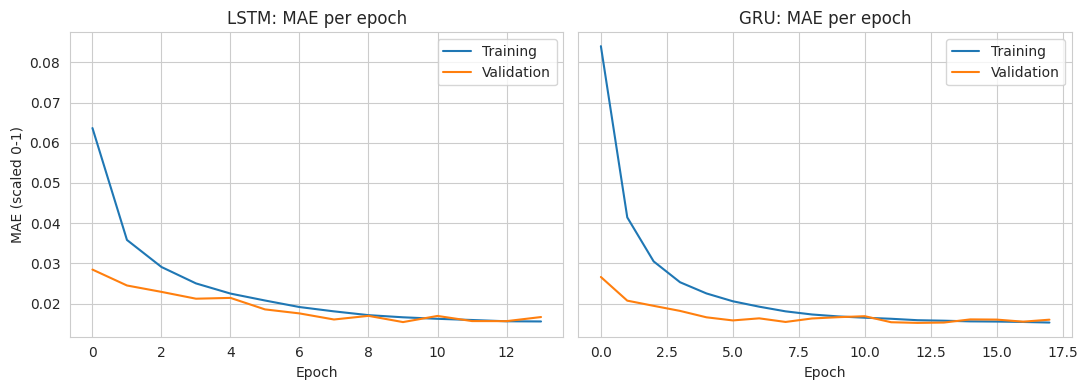

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, h, name in [(ax[0], hist_lstm, 'LSTM'), (ax[1], hist_gru, 'GRU')]:
    a.plot(h.history['mae'], label='Training')
    a.plot(h.history['val_mae'], label='Validation')
    a.set_title(name + ': MAE per epoch')
    a.set_xlabel('Epoch')
    a.legend()
ax[0].set_ylabel('MAE (scaled 0-1)')
plt.tight_layout()
plt.show()

**Observation:** Training and validation MAE fall quickly in the first 3 epochs and flatten at about 0.016 (scaled, about 15 ug/m3). The two lines stay close, so there is no overfitting. The LSTM stopped after 14 epochs and the GRU after 18.

---


### **7.3 Training / Validation Loss**

The loss is the mean squared error (MSE) per epoch.

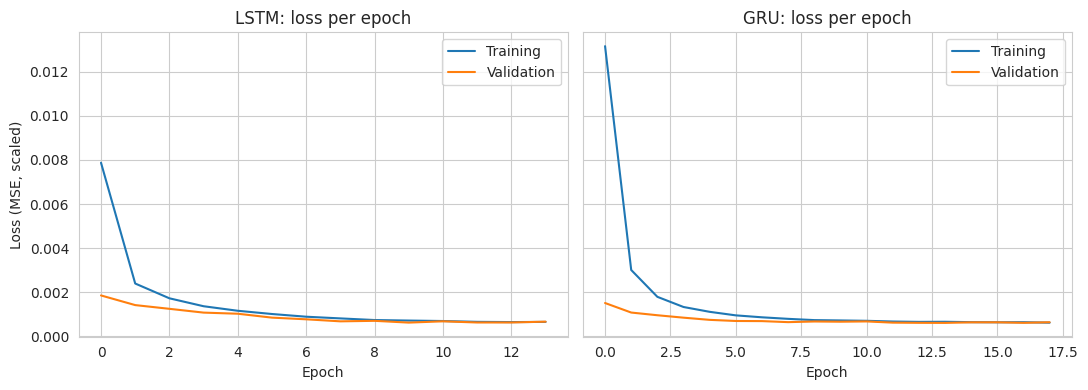

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, h, name in [(ax[0], hist_lstm, 'LSTM'), (ax[1], hist_gru, 'GRU')]:
    a.plot(h.history['loss'], label='Training')
    a.plot(h.history['val_loss'], label='Validation')
    a.set_title(name + ': loss per epoch')
    a.set_xlabel('Epoch')
    a.legend()
ax[0].set_ylabel('Loss (MSE, scaled)')
plt.tight_layout()
plt.show()

**Observation:** The loss drops sharply in the first 2 to 3 epochs and flattens at about 0.0006 (scaled). Training and validation overlap, so there is no overfitting, and early stopping ended the training in time.

---


## **8. Model Experimentation & Optimization**

### **8.1 Experiment 1 – Baseline**

**Changes:** None. The four models of Phase 2 (baseline, Random Forest, LSTM, GRU), scored on the validation year 2013.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
exp1 = pd.DataFrame({n: evaluate(val_f['pm25_scaled'], p) for n, p in preds_val.items()},
                    index=['MAE', 'RMSE', 'R2']).T
print(exp1)

                 MAE   RMSE     R2
Baseline       13.08  24.69  0.936
Random Forest  12.97  25.23  0.934
LSTM           15.35  24.84  0.936
GRU            15.23  24.58  0.937


**Results (validation 2013):** Baseline: MAE 13.08, RMSE 24.69, R2 0.936. Random Forest: MAE 12.97, RMSE 25.23, R2 0.934. LSTM: MAE 15.35, RMSE 24.84, R2 0.936. GRU: MAE 15.23, RMSE 24.58, R2 0.937. The four models are very close. The GRU is best in RMSE and R2, and the Random Forest is best in MAE.

---


### **8.2 Experiment 2 – Model Improvement**

**Changes:** The Random Forest and the GRU predict the **change** from the last hour. The last hour is then added back to get the PM2.5 prediction.

In [ ]:
last_tr, last_va, last_te = X_train_seq[:, -1, 0], X_val_seq[:, -1, 0], X_test_seq[:, -1, 0]

# GRU predicting the change
gru_change = build_model('GRU')
train_model(gru_change, y_train_seq - last_tr, y_val_seq - last_va)
preds_val['GRU (change)']  = last_va + gru_change.predict(X_val_seq,  verbose=0).ravel()
preds_test['GRU (change)'] = last_te + gru_change.predict(X_test_seq, verbose=0).ravel()

# Random Forest predicting the change
rf_change = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_change.fit(train_f[selected], train_f['pm25_scaled'] - train_f['pm25_lag1'])
preds_val['RF (change)']  = val_f['pm25_lag1'].values  + rf_change.predict(val_f[selected])
preds_test['RF (change)'] = test_f['pm25_lag1'].values + rf_change.predict(test_f[selected])

for name in ['GRU (change)', 'RF (change)']:
    print(name, '- validation (MAE, RMSE, R2):', evaluate(val_f['pm25_scaled'], preds_val[name]))

GRU (change) - validation (MAE, RMSE, R2): (13.83, 24.17, 0.939)
RF (change) - validation (MAE, RMSE, R2): (12.78, 24.86, 0.936)


**Results (validation 2013):** Predicting the change from the last hour improved both models. GRU: RMSE 24.58 to 24.17 (MAE 13.83, R2 0.939). Random Forest: RMSE 25.23 to 24.86 (MAE 12.78, R2 0.936).

---


### **8.3 Experiment 3 – Hyperparameter / Fine-Tuning**

**Changes:** The GRU is trained with other settings: 32 units, 128 units, dropout 0.3, and learning rate 0.0005. The best trained model is kept and added to the final comparison as 'Tuned GRU'.


In [ ]:
# Compare the original GRU with four alternative hyperparameter settings.
# Keep each trained model so the best setting can also be evaluated on the test year.
tuning_rows = []
tuning_candidates = []

# Include the original 64-unit GRU as the reference configuration.
original_scores = evaluate(y_val_seq, preds_val['GRU'])
tuning_rows.append([64, 0.2, 0.001, len(hist_gru.history['loss']), *original_scores])
tuning_candidates.append((original_scores[1], gru_model, 64, 0.2, 0.001))

for units, drop, lr in [(32, 0.2, 0.001), (128, 0.2, 0.001),
                        (64, 0.3, 0.001), (64, 0.2, 0.0005)]:
    candidate = build_model('GRU', units=units, dropout=drop, lr=lr)
    history = train_model(candidate)
    val_pred = candidate.predict(X_val_seq, verbose=0).ravel()
    scores = evaluate(y_val_seq, val_pred)
    tuning_rows.append([units, drop, lr, len(history.history['loss']), *scores])
    tuning_candidates.append((scores[1], candidate, units, drop, lr))

tuning_table = pd.DataFrame(
    tuning_rows,
    columns=['units', 'dropout', 'learning rate', 'epochs', 'MAE', 'RMSE', 'R2']
)
print(tuning_table)

# Select the configuration with the lowest validation RMSE.
best_tuning = min(tuning_candidates, key=lambda item: item[0])
_, best_tuned_gru_model, best_units, best_dropout, best_lr = best_tuning

# Add the tuned candidate to the common validation/test comparison.
preds_val['Tuned GRU'] = best_tuned_gru_model.predict(X_val_seq, verbose=0).ravel()
preds_test['Tuned GRU'] = best_tuned_gru_model.predict(X_test_seq, verbose=0).ravel()

print(f'Best GRU setting: units={best_units}, dropout={best_dropout}, learning_rate={best_lr}')
print('Tuned GRU validation (MAE, RMSE, R2):',
      evaluate(y_val_seq, preds_val['Tuned GRU']))


   units  dropout  learning rate  epochs    MAE   RMSE     R2
0     64      0.2         0.0010      18  15.23  24.58  0.937
1     32      0.2         0.0010      20  13.39  23.49  0.942
2    128      0.2         0.0010      20  14.82  24.37  0.938
3     64      0.3         0.0010      20  14.33  23.98  0.940
4     64      0.2         0.0005      20  13.94  23.84  0.941
Best GRU setting: units=32, dropout=0.2, learning_rate=0.001
Tuned GRU validation (MAE, RMSE, R2): (13.39, 23.49, 0.942)


**Results:** All four new settings beat the original GRU (RMSE 24.58). The best is 32 units: MAE 13.39, RMSE 23.49, R2 0.942. Next come learning rate 0.0005 (RMSE 23.84), dropout 0.3 (23.98) and 128 units (24.37). All four new settings used the full 20 epochs. The 32-unit model is kept as the Tuned GRU.

---


### **8.4 Optimization Techniques**

* **Dropout:** 0.2 in the LSTM and GRU (0.3 tested in Experiment 3), so the network does not memorise the training data.
* **Early Stopping:** patience of 4 epochs on the validation loss, with the best weights restored.
* **Hyperparameter Tuning:** units, dropout and learning rate of the GRU (Experiment 3).
* **Regularization:** the Random Forest uses a maximum depth of 12 and at least 5 samples per leaf.
* **Data Augmentation:** not used (it is not suited to this time series).
* **Fine-Tuning:** not used (no pre-trained model).

**Justification:** Dropout and early stopping keep the LSTM and GRU close to their validation scores (no overfitting). Tuning the GRU lowered the validation RMSE from 24.58 to 23.49. Predicting the change helped the GRU (24.17) and the Random Forest (24.86). The depth and leaf limits keep the Random Forest from overfitting too much, but it still overfits mildly (train RMSE 18.19, validation 25.23).

---

## **9. Model Evaluation**

### **9.1 Evaluation Metrics**

This is a regression problem, so accuracy, precision, recall, F1 score and the confusion matrix do not apply. We use:

* **MAE:** the average error in ug/m3.
* **RMSE:** like MAE, but big errors count more.
* **R2:** how much of the variation is explained (1.0 is perfect).

---

### **9.2 Model Comparison**

The models are compared on the **validation year 2013**, with all three metrics and a rank for each. The test year 2014 is not used to compare or choose models.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
# Validation 2013: all metrics for every candidate (the test year is not used here)
val_table = pd.DataFrame({name: evaluate(val_f['pm25_scaled'], preds_val[name]) for name in preds_val},
                         index=['MAE', 'RMSE', 'R2']).T
val_table['MAE rank']  = val_table['MAE'].rank(method='min').astype(int)
val_table['RMSE rank'] = val_table['RMSE'].rank(method='min').astype(int)
val_table['R2 rank']   = val_table['R2'].rank(ascending=False, method='min').astype(int)
print(val_table.sort_values('RMSE'))

                 MAE   RMSE     R2  MAE rank  RMSE rank  R2 rank
Tuned GRU      13.39  23.49  0.942         4          1        1
GRU (change)   13.83  24.17  0.939         5          2        2
GRU            15.23  24.58  0.937         6          3        3
Baseline       13.08  24.69  0.936         3          4        4
LSTM           15.35  24.84  0.936         7          5        4
RF (change)    12.78  24.86  0.936         1          6        4
Random Forest  12.97  25.23  0.934         2          7        7


**Observation:** On validation 2013 the baseline (copy the last hour) is already strong. The table shows how much each model improves on it:

| Model | MAE | RMSE | RMSE vs baseline | R2 |
|---|---|---|---|---|
| Baseline | 13.08 | 24.69 | - | 0.936 |
| Random Forest | 12.97 | 25.23 | 2.2% worse | 0.934 |
| LSTM | 15.35 | 24.84 | 0.6% worse | 0.936 |
| GRU | 15.23 | 24.58 | 0.4% better | 0.937 |
| GRU (change) | 13.83 | 24.17 | 2.1% better | 0.939 |
| RF (change) | 12.78 | 24.86 | 0.7% worse | 0.936 |
| Tuned GRU | 13.39 | 23.49 | **4.9% better** | **0.942** |

* The Random Forest and LSTM do not beat the baseline in RMSE.
* The Random Forest is slightly better in MAE (0.8%).
* Only the GRU models improve RMSE.
* The Tuned GRU gives the largest gain (24.69 to 23.49).
* The test year is not used in this table.
---

### **9.3 Best Model Selection**

The best model is chosen with the **validation** year (2013), so the test year stays an honest final exam.

In [ ]:
best = min(preds_val, key=lambda n: evaluate(val_f['pm25_scaled'], preds_val[n])[1])
print('Selected model (lowest validation RMSE):', best)
print('Its test scores (MAE, RMSE, R2):', evaluate(test_f['pm25_scaled'], preds_test[best]))

Selected model (lowest validation RMSE): Tuned GRU
Its test scores (MAE, RMSE, R2): (12.25, 21.17, 0.949)


**Selected Model and Reason:** Tuned GRU (32 units, dropout 0.2, learning rate 0.001). All three metrics were compared on the validation year 2013 (table in 9.2):

* **RMSE:** the Tuned GRU is best (23.49). Next is GRU (change) with 24.17.
* **R2:** the Tuned GRU is best (0.942).
* **MAE:** the Tuned GRU is **not** the best here. It is 4th (13.39). RF (change) 12.78, Random Forest 12.97 and the baseline 13.08 are lower.

**Why RMSE and R2 decide:**

* MAE treats every error the same.
* RMSE squares the errors, so it punishes big misses more.
* For air quality, big misses at high pollution matter most, so RMSE is the safer main metric.
* R2 shows how much of the up-and-down movement of PM2.5 the model explains, and the Tuned GRU is best here too.
* The MAE gap is small (0.61 ug/m3, about 5%).
* Most hours are normal low-pollution hours, so MAE mostly reflects them.
* The Tuned GRU also beats the baseline in RMSE (24.69 to 23.49).

**Data used:**

* Training: 2010 to 2012 (24,466 rows).
* Validation: 2013 (8,760 rows).
* Test: 2014 (8,760 rows).
* The test year was not used to compare or choose models.
* After the choice, only the selected model was scored on 2014: **MAE 12.25, RMSE 21.17, R2 0.949**.

**Interpolation check:**

* On observed-only validation rows, RF (change) is slightly better (RMSE 23.01) than the Tuned GRU (23.25).
* The rule was fixed before this check, and the Tuned GRU is best on all rows, so it stays the selected model.
* The test result of the Tuned GRU changes little on observed-only rows (RMSE 21.55 against 21.17).

**Observation:**

* Short gaps (24 hours or less) were filled by interpolation (702 values).
* A filled value is also used as an input for the next 24 hours, so one filled hour can touch up to 24 later predictions.
* A row is marked if its target hour or any of the 24 hours before it was filled.
* This touches 863 of 8,760 validation rows (9.9%) and 810 of 8,760 test rows (9.2%).

**Effect on the results:**

* On observed-only validation rows, every model's RMSE is lower (Tuned GRU 23.49 to 23.25, Random Forest 25.23 to 23.46).
* The Random Forest models are affected most.
* The ranking changes slightly: RF (change) is best on observed-only rows (RMSE 23.01, MAE 12.34, R2 0.938) and the Tuned GRU is second (RMSE 23.25, R2 0.937). The gap is small (0.24 RMSE).
* For the selected Tuned GRU on test 2014, the scores on observed-only rows are close to all rows (RMSE 21.55 against 21.17, R2 0.946 against 0.949).
* So the interpolated values do not change the final result much.

---

### **9.4 Error Analysis**

The five largest mistakes of the selected model on the test year, and the average error on normal hours compared with very polluted hours (above 300 ug/m3).

In [ ]:
y_true = to_real(test_f['pm25_scaled'])
y_pred = to_real(preds_test[best])
error = y_pred - y_true

analysis = pd.DataFrame({'datetime': test_f['datetime'].values, 'actual': y_true,
                         'predicted': y_pred, 'error': error})
print(analysis.loc[analysis['error'].abs().sort_values(ascending=False).index].head(5).round(1))

high = y_true > 300
print('MAE when actual <= 300:', round(np.abs(error[~high]).mean(), 2), '| hours:', int((~high).sum()))
if high.any():
    print('MAE when actual > 300 :', round(np.abs(error[high]).mean(), 2), '| hours:', int(high.sum()))

                datetime  actual   predicted  error
2372 2014-04-09 20:00:00   580.0   87.800003 -492.2
2373 2014-04-09 21:00:00   217.0  559.099976  342.1
721  2014-01-31 01:00:00   469.0  132.600006 -336.4
3249 2014-05-16 09:00:00   271.0   53.599998 -217.4
1362 2014-02-26 18:00:00   188.0  404.899994  216.9
MAE when actual <= 300: 11.36 | hours: 8291
MAE when actual > 300 : 28.05 | hours: 469


**Observation:**

* The biggest mistakes are sudden jumps and drops, for example 9 April 2014 (actual 580, predicted 88; then actual 217, predicted 559).
* The average error is 11.36 on normal hours and 28.05 above 300, about 2.5 times as large.

**Limitation:**

* The model makes larger errors when pollution is high. Above 300 ug/m3 the average error is 28.05, about 2.5 times the 11.36 on normal hours.
* Sudden spikes are not predicted well: on 9 April 2014 the real value was 580 but the model predicted 88.
* Such hours are rare (469 of 8,760 test hours, 5.4%).
* The model uses only the past 24 hours and weather, so a jump that starts suddenly is hard to see in advance.
* The model should be used with care for severe pollution alerts.
---


### **9.5 Overfitting / Underfitting**

RMSE of each model on the training, validation and test years. A small gap means the model generalizes well.

In [ ]:
# Training predictions for every candidate compared in Section 9.2.
last_tr = X_train_seq[:, -1, 0]
train_preds = {
    'Baseline': train_f['pm25_lag1'].values,
    'Random Forest': rf.predict(train_f[selected]),
    'LSTM': lstm_model.predict(X_train_seq, verbose=0).ravel(),
    'GRU': gru_model.predict(X_train_seq, verbose=0).ravel(),
    'GRU (change)': last_tr + gru_change.predict(X_train_seq, verbose=0).ravel(),
    'RF (change)': train_f['pm25_lag1'].values + rf_change.predict(train_f[selected]),
    'Tuned GRU': best_tuned_gru_model.predict(X_train_seq, verbose=0).ravel()
}

rows = []
for name in train_preds:
    rows.append([name,
                 evaluate(train_f['pm25_scaled'], train_preds[name])[1],
                 evaluate(val_f['pm25_scaled'], preds_val[name])[1]])
print(pd.DataFrame(rows, columns=['Model', 'Train RMSE', 'Val RMSE']).set_index('Model'))

# The test year is used only for the selected model
print('Selected model:', best, '| Test RMSE (2014):', evaluate(test_f['pm25_scaled'], preds_test[best])[1])

               Train RMSE  Val RMSE
Model                              
Baseline            24.63     24.69
Random Forest       18.19     25.23
LSTM                24.53     24.84
GRU                 24.25     24.58
GRU (change)        24.11     24.17
RF (change)         19.25     24.86
Tuned GRU           23.22     23.49
Selected model: Tuned GRU | Test RMSE (2014): 21.17


**Observation:**

* The LSTM, GRU, GRU (change) and Tuned GRU show no overfitting (train and validation RMSE are close; Tuned GRU: 23.22 and 23.49).
* The Random Forest overfits mildly (train 18.19, validation 25.23).
* RF (change) overfits a little more (19.25, 24.86).
* For the selected Tuned GRU, the test RMSE on 2014 is 21.17, which is lower than its validation RMSE, so there is no sign of overfitting.
---

**Interpolation check (observed vs interpolated hours)**

Short gaps (24 hours or less) were filled by interpolation. These filled values are part of the target and of the lag inputs, so they can affect the scores. The check below marks a row if its target hour, or any of the 24 hours before it, was interpolated. It then scores the models on all rows and on observed-only rows. Validation 2013 shows every model; test 2014 shows only the selected model.

In [ ]:
# Hours that were filled by interpolation (originally missing, now filled)
interp_hours = pd.to_datetime(df.loc[df['pm2.5'].isnull() & df['pm25_filled'].notnull(), 'datetime'])

def uses_interpolated(frame):
    # True if the predicted hour or any of the 24 hours before it was interpolated
    t = pd.to_datetime(frame['datetime'])
    flag = t.isin(interp_hours)
    for h in range(1, 25):
        flag = flag | (t - pd.Timedelta(hours=h)).isin(interp_hours)
    return flag.values

for name, frame, preds, models in [('Validation 2013', val_f, preds_val, list(preds_val)),
                                   ('Test 2014 (selected model only)', test_f, preds_test, [best])]:
    flag = uses_interpolated(frame)
    print(f'{name}: {len(frame)} rows, {flag.sum()} use interpolated data ({flag.mean() * 100:.1f}%)')
    y = frame['pm25_scaled'].values
    rows = []
    for model in models:
        p = np.asarray(preds[model])
        rows.append([model, *evaluate(y, p), *evaluate(y[~flag], p[~flag])])
    print(pd.DataFrame(rows, columns=['Model', 'MAE all', 'RMSE all', 'R2 all',
                                      'MAE observed', 'RMSE observed', 'R2 observed']).set_index('Model'))
    print()

Validation 2013: 8760 rows, 863 use interpolated data (9.9%)
               MAE all  RMSE all  R2 all  MAE observed  RMSE observed  \
Model                                                                   
Baseline         13.08     24.69   0.936         12.93          24.48   
Random Forest    12.97     25.23   0.934         12.53          23.46   
LSTM             15.35     24.84   0.936         15.21          24.57   
GRU              15.23     24.58   0.937         15.12          24.34   
GRU (change)     13.83     24.17   0.939         13.70          23.93   
RF (change)      12.78     24.86   0.936         12.34          23.01   
Tuned GRU        13.39     23.49   0.942         13.29          23.25   

               R2 observed  
Model                       
Baseline             0.930  
Random Forest        0.936  
LSTM                 0.930  
GRU                  0.931  
GRU (change)         0.933  
RF (change)          0.938  
Tuned GRU            0.937  

Test 2014 (selected

**Observation:** Interpolated data touches 863 of 8,760 validation rows (9.9%) and 810 of 8,760 test rows (9.2%). On observed-only validation rows, every model's RMSE is lower (for example Tuned GRU 23.49 to 23.25 and Random Forest 25.23 to 23.46). The ranking changes slightly: RF (change) is best on observed-only rows (RMSE 23.01, MAE 12.34, R2 0.938) and the Tuned GRU is second (RMSE 23.25, R2 0.937). The gap between them is small (0.24 RMSE). For the selected Tuned GRU on test 2014, observed-only scores are close to all rows (RMSE 21.55 against 21.17, R2 0.946 against 0.949), so the interpolated values do not change the test result much.

**Final decisions (summary)**

* **Missing values:** gaps of 24 hours or less are filled by linear interpolation (702 values). Longer gaps stay empty (1,365 values), and 1,838 rows are removed before training (empty target or lag).
* **Interpolated values:** they are part of the target and the lag inputs. The interpolation check above compares scores on all rows and on observed-only rows.
* **Features:** 20 candidate features were scored with SelectKBest and the best 18 are kept for the Random Forest. The LSTM and GRU use 24 hours x 15 values.
* **Data split:** training 2010 to 2012, validation 2013, test 2014. Models are compared and chosen on 2013 only.
* **Selection rule:** all metrics (MAE, RMSE, R2) are compared. The lowest validation RMSE decides, with the reasons given in 9.3.
* **Selected model:** Tuned GRU (32 units, dropout 0.2, learning rate 0.001). Test 2014: MAE 12.25, RMSE 21.17, R2 0.949.
* **Prediction:** the model reads the previous 24 hours and predicts the next hour. Training and prediction use the same lags, scaling and feature order.

<font color="197AA6" size=5px><b>PHASE 4 – DEPLOYMENT & DOCUMENTATION</b></font>

Save the final model, serve it with an API, package it with Docker and document the project.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

## **10. Model Export**

Save the final model (Tuned GRU) and the target scaler, so the API can use them without retraining.

* **Model file format:** `.keras` (model) and `.pkl` (target scaler).
* **Location:** the `app` folder of the project (`model.keras`, `target_scaler.pkl`).

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [ ]:
import os

APP_DIR = "/content/drive/MyDrive/beijing-pm25-prediction/app"
os.makedirs(APP_DIR, exist_ok=True)

# Export model and scaler into the project app folder
best_tuned_gru_model.save(os.path.join(APP_DIR, "model.keras"))

import joblib
joblib.dump(target_scaler, os.path.join(APP_DIR, "target_scaler.pkl"))

print("Model and scaler saved in:", APP_DIR)

Model and scaler saved in: /content/drive/MyDrive/beijing-pm25-prediction/app


## **11. API Deployment**

### **11.1 Technology Used**

* **FastAPI** (served with Uvicorn).
* Why: short code, automatic input checks and a built-in test page (`/docs`).

### **11.2 API Endpoint**

* `GET /` : home message.
* `GET /health` : API status.
* `POST /predict` : next-hour PM2.5.

**Input:** the previous 24 hours, 15 scaled values per hour, in the training column order.

```
{"sequence": [[15 values for hour 1], [15 values for hour 2], ... , [15 values for hour 24]]}
```

**Output:**

```
{"predicted_pm25": <number>, "unit": "µg/m³"}
```

* There is no "confidence" value, because this is a regression model (it predicts a number, not a class).
* A wrong input shape returns status 400.

### **11.3 API Implementation**

`app.py` loads the model and the scaler, checks the input shape, predicts, and converts the answer back to µg/m³.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [1]:
!pip install fastapi uvicorn

In [5]:

%%writefile /content/drive/MyDrive/beijing-pm25-prediction/app/app.py

import os
import joblib
import numpy as np
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from tensorflow.keras.models import load_model

# Project app folder
BASE_DIR = os.path.dirname(os.path.abspath(__file__))

# Load model and scaler
model = load_model(os.path.join(BASE_DIR, "model.keras"))
target_scaler = joblib.load(
    os.path.join(BASE_DIR, "target_scaler.pkl")
)

# Create API
app = FastAPI(
    title="Beijing PM2.5 Prediction API",
    description="Predicts next-hour PM2.5 from the previous 24 hours.",
    version="1.0.0"
)

class PredictionRequest(BaseModel):
    sequence: list[list[float]] = Field(
        ...,
        description="24 hours × 15 preprocessed and scaled features"
    )

@app.get("/")
def home():
    return {"message": "Beijing PM2.5 Prediction API"}

@app.get("/health")
def health():
    return {"status": "healthy"}

@app.post("/predict")
def predict(request: PredictionRequest):
    data = np.asarray(request.sequence, dtype=float)

    if data.shape != (24, 15):
        raise HTTPException(
            status_code=400,
            detail="Input must contain exactly 24 rows and 15 features."
        )

    if not np.isfinite(data).all():
        raise HTTPException(
            status_code=400,
            detail="Input must contain only finite numeric values."
        )

    prediction_scaled = model.predict(
        data.reshape(1, 24, 15),
        verbose=0
    )

    prediction = target_scaler.inverse_transform(
        prediction_scaled.reshape(-1, 1)
    )[0, 0]

    return {
        "predicted_pm25": float(prediction),
        "unit": "µg/m³"
    }

Overwriting /content/drive/MyDrive/beijing-pm25-prediction/app/app.py


**Check that the model and the scaler load.** The model input shape must be (None, 24, 15).

In [6]:
import os
import joblib
from tensorflow.keras.models import load_model

APP_DIR = "/content/drive/MyDrive/beijing-pm25-prediction/app"

model_path = os.path.join(APP_DIR, "model.keras")
scaler_path = os.path.join(APP_DIR, "target_scaler.pkl")

print("Model file exists:", os.path.exists(model_path))
print("Scaler file exists:", os.path.exists(scaler_path))

model = load_model(model_path)
target_scaler = joblib.load(scaler_path)

print("Model loaded successfully!")
print("Scaler loaded successfully!")
print("Model input shape:", model.input_shape)

Model file exists: True
Scaler file exists: True
Model loaded successfully!
Scaler loaded successfully!
Model input shape: (None, 24, 15)


**API testing: home and health endpoints.**

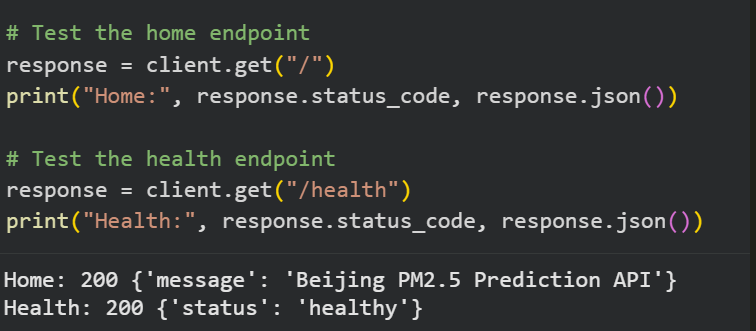

In [ ]:
#@title Screenshot: home and health test
from IPython.display import Image, display
try:
    display(Image('/content/drive/MyDrive/beijing-pm25-prediction/reports/screenshots/1a_home_health.png'))
except Exception:
    print('Screenshot file not found in reports/screenshots')


In [7]:
import sys

APP_DIR = "/content/drive/MyDrive/beijing-pm25-prediction/app"

if APP_DIR not in sys.path:
    sys.path.insert(0, APP_DIR)

from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

# Test the home endpoint
response = client.get("/")
print("Home:", response.status_code, response.json())

# Test the health endpoint
response = client.get("/health")
print("Health:", response.status_code, response.json())

Home: 200 {'message': 'Beijing PM2.5 Prediction API'}
Health: 200 {'status': 'healthy'}


**API testing: `/predict` with a real validation sample.** The API value must be the same as the model value. A wrong shape must return status 400.

*API testing output: see the cell output below (status 200, API equals model, wrong shape gives 400).*

In [8]:
# Test /predict with a REAL validation sample (not zeros)
import numpy as np

seq = np.load("/content/drive/MyDrive/beijing-pm25-prediction/data/processed/sequences.npz")
sample = seq["X_val"][:1]
real_value = float(target_scaler.inverse_transform(seq["y_val"][:1].reshape(-1, 1))[0, 0])

response = client.post("/predict", json={"sequence": sample[0].tolist()})
api_value = response.json()["predicted_pm25"]

model_value = float(target_scaler.inverse_transform(model.predict(sample, verbose=0).reshape(-1, 1))[0, 0])

print("Status code:", response.status_code)
print("API response:", response.json())
print("Model value :", round(model_value, 2))
print("Real PM2.5  :", round(real_value, 2))
print("API equals model:", abs(api_value - model_value) < 0.01)

# A wrong input shape must be rejected
bad = client.post("/predict", json={"sequence": np.zeros((10, 15)).tolist()})
print("Wrong shape ->", bad.status_code, bad.json())

Status code: 200
API response: {'predicted_pm25': 58.13604736328125, 'unit': 'µg/m³'}
Model value : 58.14
Real PM2.5  : 35.0
API equals model: True
Wrong shape -> 400 {'detail': 'Input must contain exactly 24 rows and 15 features.'}


## **12. Docker Containerization**

### **12.1 Dockerfile**

The next cell reads only the files saved on Drive (no need to rerun Phases 1 to 3). It makes `app.py` work inside Docker, and writes `requirements.txt`, `Dockerfile`, `.dockerignore`, `sample_request.json` and `README.md` in the project folder.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [9]:
# Phase 4 - Docker files, README and sample request
# Runs on its own: it reads only the files saved on Drive. No need to rerun Phases 1 to 3.
!pip install -q fastapi uvicorn

import os, re, sys, json, joblib
import numpy as np
import fastapi, uvicorn, pydantic, sklearn
import tensorflow as tf
from tensorflow.keras.models import load_model
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/beijing-pm25-prediction"
APP_DIR = PROJECT_DIR + "/app"

# 1. Load the saved model, scaler and validation blocks from Drive
model = load_model(APP_DIR + "/model.keras")
target_scaler = joblib.load(APP_DIR + "/target_scaler.pkl")
seq = np.load(PROJECT_DIR + "/data/processed/sequences.npz")
X_val_seq, y_val_seq = seq["X_val"], seq["y_val"]

# The 15 columns of one hour, in training order (same as seq_cols in Section 5.2)
weather_cols = ['DEWP', 'TEMP', 'PRES', 'Iws', 'Is', 'Ir', 'wind_NE', 'wind_NW', 'wind_SE', 'wind_cv']
seq_cols = ['pm25_scaled'] + weather_cols + ['hour_sin', 'hour_cos', 'month_sin', 'month_cos']
assert len(seq_cols) == X_val_seq.shape[2] == 15

# 2. Make app.py work inside Docker (use its own folder instead of the Drive path)
code = open(APP_DIR + "/app.py").read()
code = re.sub(r'^BASE_DIR\s*=.*$', 'BASE_DIR = os.path.dirname(os.path.abspath(__file__))', code, flags=re.M)
open(APP_DIR + "/app.py", "w").write(code)

# 3. requirements.txt (same versions as this Colab, so the model loads the same way)
requirements = "\n".join([
    f"fastapi=={fastapi.__version__}",
    f"uvicorn=={uvicorn.__version__}",
    f"pydantic=={pydantic.__version__}",
    f"tensorflow-cpu=={tf.__version__}",
    f"numpy=={np.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}",
]) + "\n"
open(PROJECT_DIR + "/requirements.txt", "w").write(requirements)

# 4. Dockerfile and .dockerignore
py = f"{sys.version_info.major}.{sys.version_info.minor}"
dockerfile = f"""FROM python:{py}-slim
WORKDIR /code
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app ./app
EXPOSE 8000
CMD ["uvicorn", "app:app", "--app-dir", "app", "--host", "0.0.0.0", "--port", "8000"]
"""
open(PROJECT_DIR + "/Dockerfile", "w").write(dockerfile)
open(PROJECT_DIR + "/.dockerignore", "w").write("__pycache__/\n*.pyc\n.ipynb_checkpoints/\n")

# 5. A real sample request (first validation block) and the value the model gives for it
sample = X_val_seq[:1]
pred_scaled = model.predict(sample, verbose=0).reshape(-1, 1)
expected = float(target_scaler.inverse_transform(pred_scaled)[0, 0])
actual = float(target_scaler.inverse_transform(np.asarray(y_val_seq[:1]).reshape(-1, 1))[0, 0])
json.dump({"sequence": sample[0].tolist()}, open(PROJECT_DIR + "/sample_request.json", "w"))

# 6. README.md
columns = "\n".join(f"{i + 1}. `{c}`" for i, c in enumerate(seq_cols))
readme = f"""# Beijing PM2.5 Prediction API

Predicts the PM2.5 of the **next hour** from the **previous 24 hours**.

## Model
- Selected model: Tuned GRU (32 units, dropout 0.2, learning rate 0.001).
- Chosen on the validation year 2013 (RMSE 23.49, R2 0.942).
- Test year 2014 (selected model only): MAE 12.25, RMSE 21.17, R2 0.949.
- Data split: training 2010 to 2012, validation 2013, test 2014.

## Input
- 24 rows (hours) x 15 columns, **already scaled** with the saved scalers.
- The column order must be exactly the same as in training:

{columns}

## Output
- JSON with `predicted_pm25` and `unit` (ug/m3) for the next hour.
- No "confidence" value is given, because this is a regression model (it predicts a number, not a class).

## Run with Docker
```
docker build -t beijing-pm25-api .
docker run -p 8000:8000 beijing-pm25-api
```
Open http://localhost:8000/docs to test the API.

## Test with the sample request
```
curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" -d @sample_request.json
```
- The notebook gives {expected:.2f} for this sample. The API should return the same value.
- The real PM2.5 of that hour was {actual:.2f}.

## Limitations
- Errors are larger at high pollution (average error 28.05 above 300, against 11.36 on normal hours).
- Sudden pollution spikes are not predicted well.
- About 10% of the rows use interpolated values.
- The input must use the same scaling and column order as in training.

## Files
- `app/app.py`: the FastAPI app.
- `app/model.keras`: the trained Tuned GRU model.
- `app/target_scaler.pkl`: converts the model output back to ug/m3.
- `Dockerfile`, `requirements.txt`, `.dockerignore`: Docker setup.
- `sample_request.json`: a real example input.
"""
open(PROJECT_DIR + "/README.md", "w").write(readme)

print("Files written to:", PROJECT_DIR)
print(sorted(os.listdir(PROJECT_DIR)))
print("BASE_DIR line now:", [l for l in code.splitlines() if l.startswith("BASE_DIR")])
print("Model prediction for the sample:", round(expected, 2), "| real value:", round(actual, 2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files written to: /content/drive/MyDrive/beijing-pm25-prediction
['.dockerignore', 'Dockerfile', 'README.md', 'app', 'data', 'models', 'notebooks', 'reports', 'requirements.txt', 'sample_request.json']
BASE_DIR line now: ['BASE_DIR = os.path.dirname(os.path.abspath(__file__))']
Model prediction for the sample: 58.14 | real value: 35.0


In [10]:
# Show the Dockerfile and the requirements
print(open(PROJECT_DIR + "/Dockerfile").read())
print(open(PROJECT_DIR + "/requirements.txt").read())

FROM python:3.13-slim
WORKDIR /code
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app ./app
EXPOSE 8000
CMD ["uvicorn", "app:app", "--app-dir", "app", "--host", "0.0.0.0", "--port", "8000"]

fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.1
tensorflow-cpu==2.21.0
numpy==2.1.3
scikit-learn==1.6.1
joblib==1.6.0



### **12.2 Docker Build**

Run this on the laptop, in a terminal inside the project folder (`beijing-pm25-prediction`):

```
docker build -t beijing-pm25-api .
```

*Screenshot: Docker Build Success.*

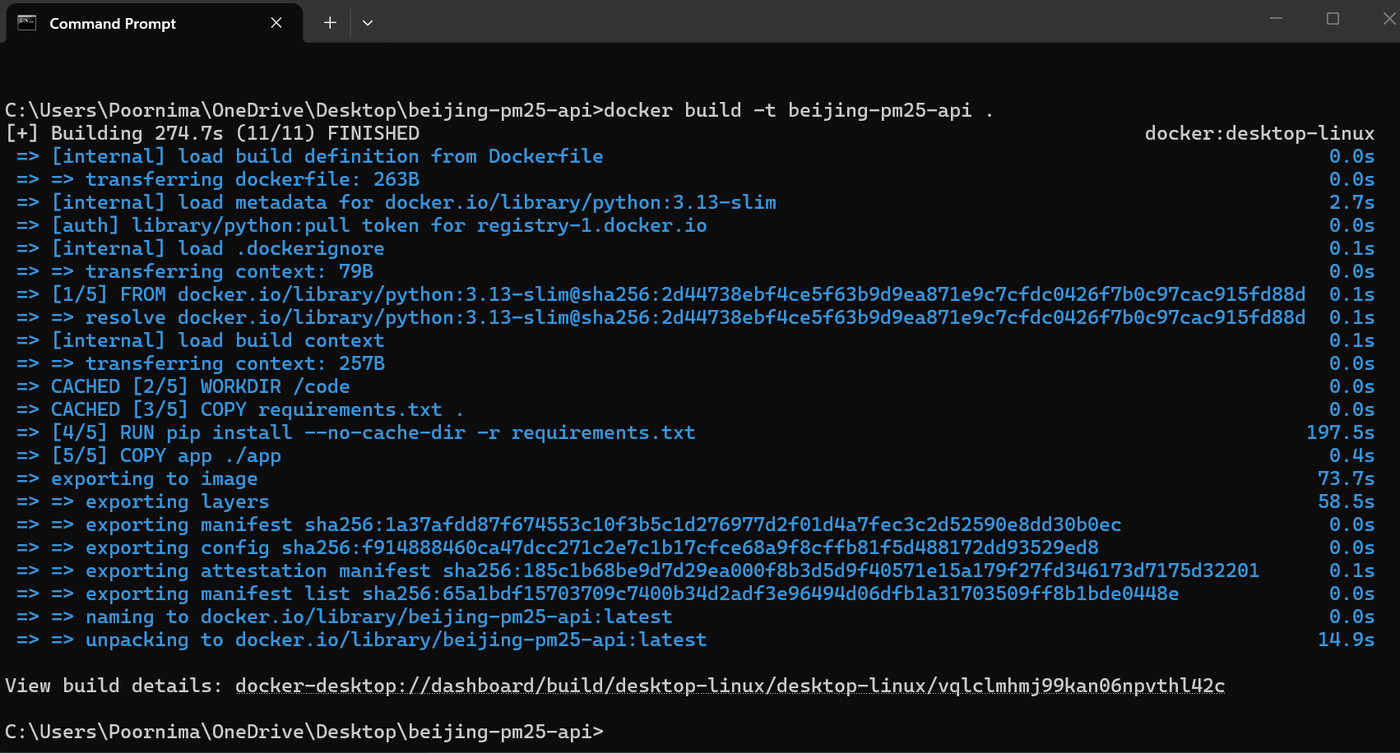

In [ ]:
#@title Screenshot: Docker build success
from IPython.display import Image, display
try:
    display(Image('/content/drive/MyDrive/beijing-pm25-prediction/reports/screenshots/2_docker_build.png'))
except Exception:
    print('Screenshot file not found in reports/screenshots')


### **12.3 Docker Run**

```
docker run -p 8000:8000 beijing-pm25-api
```

Open `http://localhost:8000/docs` and test `POST /predict` with `sample_request.json`. The value must match the model value printed in 12.1.

*Screenshot: Docker Run Success (left: container running, right: health check).*

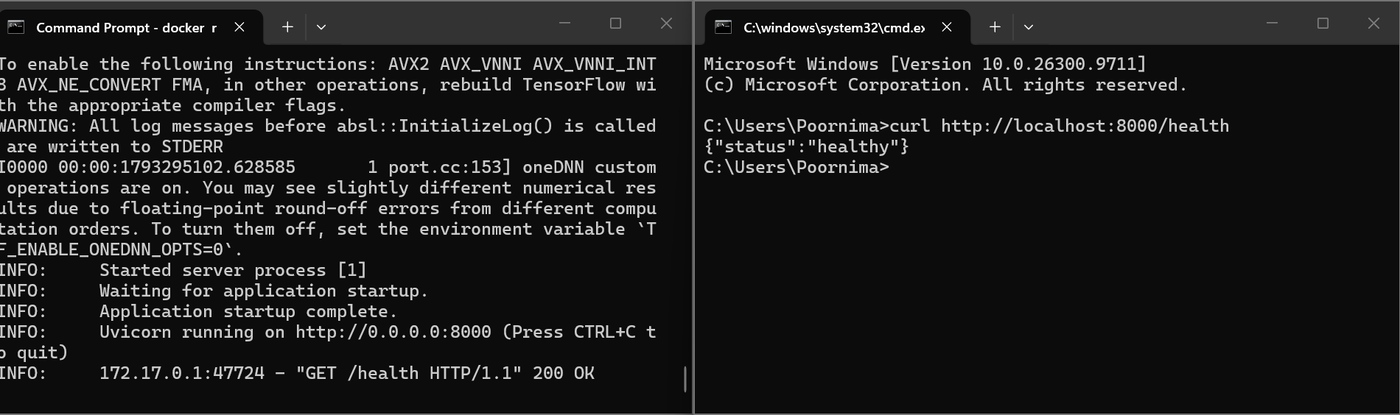

In [ ]:
#@title Screenshot: Docker run success
from IPython.display import Image, display
try:
    display(Image('/content/drive/MyDrive/beijing-pm25-prediction/reports/screenshots/3_docker_run.png'))
except Exception:
    print('Screenshot file not found in reports/screenshots')


*Screenshot: API Response (request and response at localhost:8000/docs).*

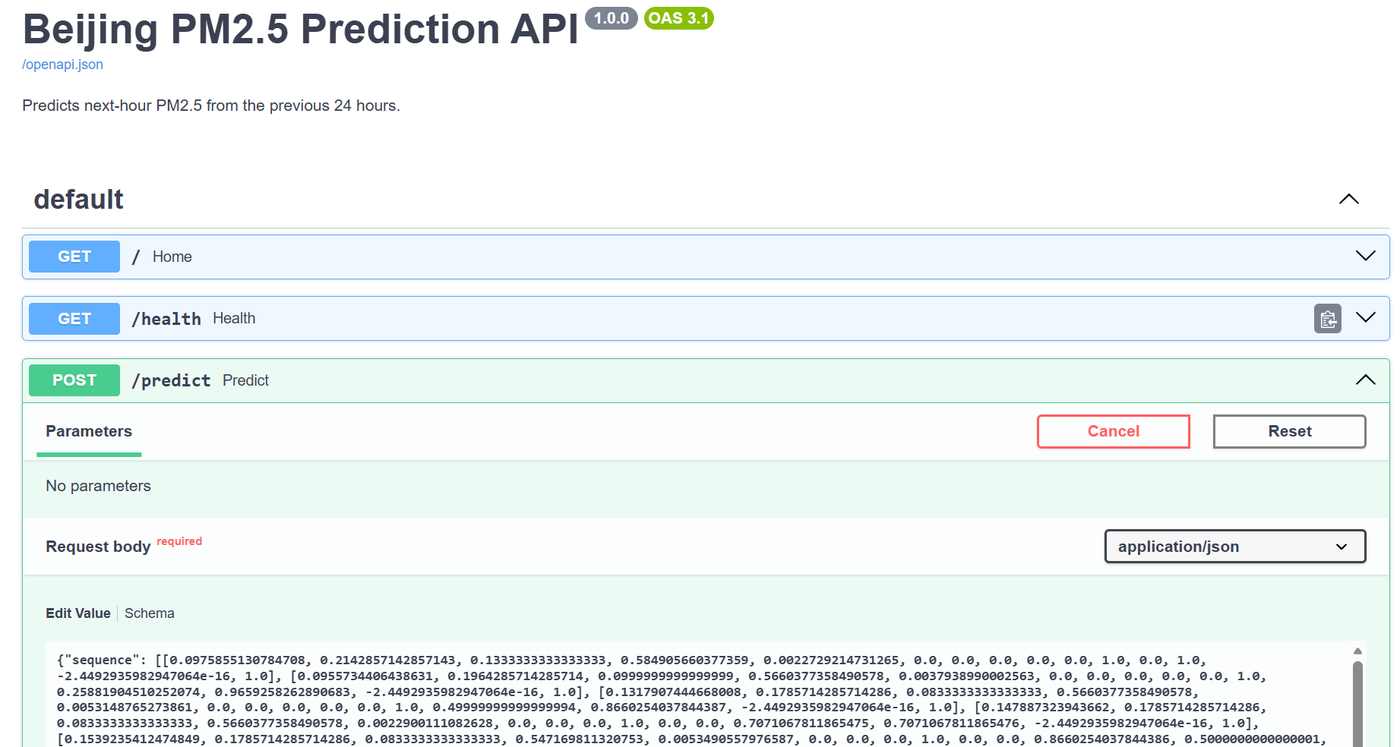

In [ ]:
#@title Screenshot: API request
from IPython.display import Image, display
try:
    display(Image('/content/drive/MyDrive/beijing-pm25-prediction/reports/screenshots/4a_api_request.png'))
except Exception:
    print('Screenshot file not found in reports/screenshots')


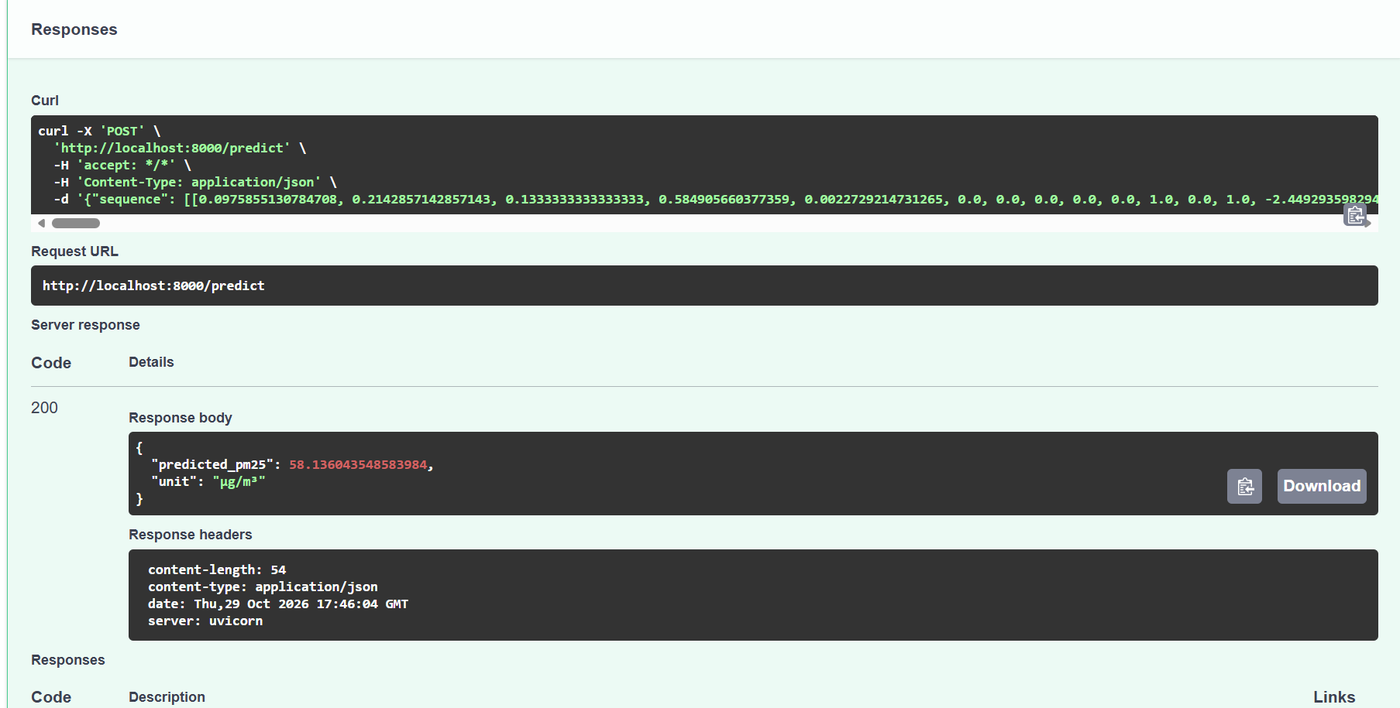

In [ ]:
#@title Screenshot: API response
from IPython.display import Image, display
try:
    display(Image('/content/drive/MyDrive/beijing-pm25-prediction/reports/screenshots/4_api_response.png'))
except Exception:
    print('Screenshot file not found in reports/screenshots')


## **13. Documentation**

### **13.1 README.md**

The README is saved in the project folder. It covers: project overview, problem statement, dataset, technologies used, model details, installation, API usage, Docker instructions, results, limitations and future improvements.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)

In [11]:
# Show the README
print(open(PROJECT_DIR + "/README.md").read())

# Beijing PM2.5 Prediction API

Predicts the PM2.5 of the **next hour** from the **previous 24 hours**.

## Model
- Selected model: Tuned GRU (32 units, dropout 0.2, learning rate 0.001).
- Chosen on the validation year 2013 (RMSE 23.49, R2 0.942).
- Test year 2014 (selected model only): MAE 12.25, RMSE 21.17, R2 0.949.
- Data split: training 2010 to 2012, validation 2013, test 2014.

## Input
- 24 rows (hours) x 15 columns, **already scaled** with the saved scalers.
- The column order must be exactly the same as in training:

1. `pm25_scaled`
2. `DEWP`
3. `TEMP`
4. `PRES`
5. `Iws`
6. `Is`
7. `Ir`
8. `wind_NE`
9. `wind_NW`
10. `wind_SE`
11. `wind_cv`
12. `hour_sin`
13. `hour_cos`
14. `month_sin`
15. `month_cos`

## Output
- JSON with `predicted_pm25` and `unit` (ug/m3) for the next hour.
- No "confidence" value is given, because this is a regression model (it predicts a number, not a class).

## Run with Docker
```
docker build -t beijing-pm25-api .
docker run -p 8000:8000 beijing-pm25

## **14. Conclusion**

### **14.1 Final Findings**

* **Problem solved:** the next-hour PM2.5 in Beijing is predicted from the previous 24 hours.
* **Dataset used:** UCI Beijing PM2.5, 43,824 hourly rows (2010 to 2014). Training 2010 to 2012, validation 2013, test 2014.
* **Best model:** Tuned GRU (32 units, dropout 0.2, learning rate 0.001), chosen on validation RMSE and R2.
* **Final performance (test 2014):** MAE 12.25, RMSE 21.17, R2 0.949.
* **Key findings:**
  * The baseline (copy the last hour) is strong, because the last hour is correlated 0.97 with the next.
  * The Tuned GRU lowers the baseline RMSE by 4.9% on the validation year (24.69 to 23.49).
  * About 10% of the rows use interpolated values, but the final result stays almost the same.
  * Errors are larger at high pollution (28.05 above 300, against 11.36 on normal hours). Sudden spikes are not predicted well.

### **14.2 Business Impact**

* City authorities and schools can plan for the next hour, for example outdoor activities and warnings.
* People with breathing problems can get an early notice.
* The API and Docker image let other systems (a dashboard or a mobile app) use the model easily.
* It should not be the only source for severe pollution alerts, because sudden spikes are not predicted well.

### **14.3 Future Improvements**

* **More data:** more years, more stations, more weather and event data.
* **Better models:** models built to handle sudden spikes, and ensembles.
* **Cloud deployment:** host the Docker container on a cloud service.
* **Real-time implementation:** feed live readings and build the 24-hour window automatically.
* **MLOps / model monitoring:** track the errors over time and retrain when the scores drop.

[⬆ Back to Contents](#scrollTo=8f1b46c5607e)